# Injury crash risk ranking: College Station, TX

Predicts which road segments and intersections are most likely to have KABC (fatal or injury) crashes next year, and backtests the prediction with rolling-origin and leave-city-out splits.

**How to run in Colab:** put the TxDOT CRIS Query CSV exports in `MyDrive/crash_risk/cris/`, then Runtime > Run all and approve the Drive popup. Outputs go to `MyDrive/crash_risk/outputs/`.

## 0. Environment
Detects Colab, mounts Drive, and sets `DRIVE_ROOT`. Outside Colab it uses `./crash_risk_data`.

In [ ]:
import os, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/crash_risk'
else:
    DRIVE_ROOT = os.path.abspath('./crash_risk_data')
os.makedirs(DRIVE_ROOT, exist_ok=True)
print('IN_COLAB =', IN_COLAB, '| DRIVE_ROOT =', DRIVE_ROOT)

Mounted at /content/drive
IN_COLAB = True | DRIVE_ROOT = /content/drive/MyDrive/crash_risk


## 1. Packages
Installs only what is missing (on Colab that is usually just osmnx), then prints versions.

In [ ]:
import importlib, importlib.util, subprocess

REQUIRED = {'osmnx': 'osmnx>=2.0', 'geopandas': 'geopandas>=1.0', 'lightgbm': 'lightgbm', 'statsmodels': 'statsmodels',
            'folium': 'folium', 'pyarrow': 'pyarrow', 'pyogrio': 'pyogrio', 'scipy': 'scipy',
            'matplotlib': 'matplotlib', 'requests': 'requests', 'shapely': 'shapely>=2.0'}
missing = [spec for mod, spec in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if importlib.util.find_spec('osmnx') is not None:
    import osmnx as _ox
    if int(_ox.__version__.split('.')[0]) < 2:
        missing.append('osmnx>=2.0')
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    importlib.invalidate_caches()

VERSIONS = {}
for mod in ['numpy', 'pandas', 'geopandas', 'shapely', 'pyproj', 'osmnx', 'lightgbm', 'statsmodels', 'folium', 'scipy', 'matplotlib', 'pyarrow']:
    VERSIONS[mod] = importlib.import_module(mod).__version__
VERSIONS['python'] = sys.version.split()[0]
print(VERSIONS)

Installing: ['osmnx>=2.0']
{'numpy': '2.4.6', 'pandas': '2.2.3', 'geopandas': '1.2.0', 'shapely': '2.2.0', 'pyproj': '3.8.0', 'osmnx': '2.1.1', 'lightgbm': '4.6.0', 'statsmodels': '0.15.0', 'folium': '0.20.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'pyarrow': '23.0.1', 'python': '3.13.18'}


## 2. CONFIG
Every tunable lives here. `SMOKE_TEST = True` runs College Station and Bryan only, with one test year and 100 bootstrap draws.

In [ ]:
CONFIG = dict(
    CITIES=['College Station', 'Bryan', 'Waco', 'San Marcos', 'Denton', 'Lubbock', 'Temple', 'Killeen',
            'Tyler', 'Round Rock', 'Huntsville'],
    TARGET_CITY='College Station',
    TEST_CITIES=['College Station', 'Bryan'],   # scored in the backtest; the MPO HIN covers both
    HIST_YEARS_LONG=5,              # long crash-history window for EB and features
    SMOKE_TEST=False,
    FORCE_REFRESH=False,
    SEED=42,
    CRS_M='EPSG:3083',
    COMPLETE_LAG_MONTHS=6,          # a year is complete if it ended this many months before the latest crash date
    MIN_CITY_CRASHES=50,            # cities with fewer geocoded crashes inside the polygon are skipped
    TIGER_URLS=['https://www2.census.gov/geo/tiger/TIGER2024/PLACE/tl_2024_48_place.zip',
                'https://www2.census.gov/geo/tiger/TIGER2023/PLACE/tl_2023_48_place.zip'],
    INVENTORY_URL='https://services.arcgis.com/KTcxiTD9dsQw4r7Z/arcgis/rest/services/TxDOT_Roadway_Inventory/FeatureServer/0',
    INVENTORY_FIELDS=['RIA_RTE_ID', 'HWY', 'HSYS', 'HNUM', 'STE_NAM', 'RDBD_ID', 'F_SYSTEM', 'ADT_CUR', 'ADT_YEAR',
                      'SPD_MAX', 'NUM_LANES', 'LANE_WIDTH', 'MED_TYPE', 'ACES_CTRL', 'RT_TURN_LANE', 'LT_TURN_LANE',
                      'TRK_AADT_PCT', 'SRF_TYPE'],
    MAIN_RDBD=['KG', 'AG', 'XG'],   # KG main lanes, AG/XG frontage roads
    SPLIT_RDBD=['LG', 'RG'],        # divided-roadbed lines that duplicate KG; kept only where no KG is nearby
    SPLIT_RDBD_DUP_M=60,
    HTTP_RETRIES=6,
    SEG_LEN_M=321.869,              # 0.2 mi
    SEG_MIN_REMAINDER_M=160.934,    # 0.1 mi
    INT_CONSOLIDATE_M=15,
    INT_MIN_STREETS=3,
    AADT_SEARCH_M=25,
    SIGNAL_M=30,
    CROSSING_M=30,
    SEG_INT_M=20,                   # intersections within this distance count toward intersections per mile
    POI_M=200,
    BUS_M=100,
    UNIV_SEARCH_M=5000,            # distance to university is capped here
    OSM_BUFFER_M=300,
    SNAP_TOL_M=50,
    INT_SNAP_M=76,
    HIN_M=30,
    N_TEST_YEARS=3,
    N_BOOT=1000,
    SHARES=[0.05, 0.11, 0.20],     # 11% = the HIN's share (FSR); 5% and 20% are sensitivity
    LGB_PARAMS=dict(objective='poisson', learning_rate=0.03, num_leaves=15, min_data_in_leaf=50,
                    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                    verbose=-1, deterministic=True, force_row_wise=True),
    LGB_MAX_ROUNDS=2000,
    LGB_SEEDS=[42, 7, 2026],       # seed bagging: average 3 boosters
    BACKTEST_CUTOFF_YEAR=2022,     # FSR split: train on <= 2022, score pooled 2023-2025
    NEIGHBOR_M=250,                # spatial-lag radius
    SEV_PRIOR_M=10,                # pseudo-crashes shrinking a site's own KA share toward the severity model
    HIN_OVERLAP=0.5,               # ICD Table 5: a segment is on the HIN if >= 50% of it is within HIN_M
    TXDOT_SYSTEMS=['IH', 'US', 'SH', 'FM', 'RM', 'BS', 'BU', 'BF', 'BI', 'SL', 'SS', 'SP', 'RR', 'PR', 'UA', 'UP', 'TL'],
    LGB_EARLY_STOP=100,
)
if CONFIG['SMOKE_TEST']:
    CONFIG.update(CITIES=['College Station', 'Bryan'], N_TEST_YEARS=1, N_BOOT=100)

CRIS_DIR = os.path.join(DRIVE_ROOT, 'cris')
CACHE_DIR = os.path.join(DRIVE_ROOT, 'cache')
OUT_DIR = os.path.join(DRIVE_ROOT, 'outputs')
INPUTS_DIR = os.path.join(DRIVE_ROOT, 'inputs')
for d in [CRIS_DIR, CACHE_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)
CONFIG

{'CITIES': ['College Station',
  'Bryan',
  'Waco',
  'San Marcos',
  'Denton',
  'Lubbock',
  'Temple',
  'Killeen',
  'Tyler',
  'Round Rock',
  'Huntsville'],
 'TARGET_CITY': 'College Station',
 'TEST_CITIES': ['College Station', 'Bryan'],
 'HIST_YEARS_LONG': 5,
 'SMOKE_TEST': False,
 'FORCE_REFRESH': False,
 'SEED': 42,
 'CRS_M': 'EPSG:3083',
 'COMPLETE_LAG_MONTHS': 6,
 'MIN_CITY_CRASHES': 50,
 'TIGER_URLS': ['https://www2.census.gov/geo/tiger/TIGER2024/PLACE/tl_2024_48_place.zip',
  'https://www2.census.gov/geo/tiger/TIGER2023/PLACE/tl_2023_48_place.zip'],
 'INVENTORY_URL': 'https://services.arcgis.com/KTcxiTD9dsQw4r7Z/arcgis/rest/services/TxDOT_Roadway_Inventory/FeatureServer/0',
 'INVENTORY_FIELDS': ['RIA_RTE_ID',
  'HWY',
  'HSYS',
  'HNUM',
  'STE_NAM',
  'RDBD_ID',
  'F_SYSTEM',
  'ADT_CUR',
  'ADT_YEAR',
  'SPD_MAX',
  'NUM_LANES',
  'LANE_WIDTH',
  'MED_TYPE',
  'ACES_CTRL',
  'RT_TURN_LANE',
  'LT_TURN_LANE',
  'TRK_AADT_PCT',
  'SRF_TYPE'],
 'MAIN_RDBD': ['KG', 'AG', 'XG'

## 3. Helper functions
Pure functions used by the stages below: CRIS parsing, name normalization, segmentation, snapping, Empirical Bayes, and capture metrics. The unit tests exercise this cell directly.

In [ ]:
# HELPERS
import io, re, math, json, time, glob, hashlib, pickle, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import LineString, MultiLineString, Point
from shapely.ops import substring, linemerge, unary_union
import requests

LOG_LINES = []
LOG_PATH = None


def log(*parts):
    msg = ' '.join(str(p) for p in parts)
    print(msg)
    LOG_LINES.append(msg)
    if LOG_PATH:
        with open(LOG_PATH, 'a') as f:
            f.write(msg + '\n')


# ---------- CRIS ----------
CRIS_NA = ['No Data', 'N/A', '']


def read_cris_csv(path):
    """Read a CRIS Query export: skip the preamble, handle the BOM and CRLF, return all columns as str."""
    with open(path, encoding='utf-8-sig', newline='') as f:
        text = f.read()
    lines = text.splitlines(keepends=True)
    idx = next((i for i, l in enumerate(lines) if l.lstrip('﻿').lstrip('"').startswith('Crash ID')), None)
    if idx is None:
        raise ValueError(f'{path}: no header line starting with "Crash ID"')
    df = pd.read_csv(io.StringIO(''.join(lines[idx:])), dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    return df.replace({v: np.nan for v in CRIS_NA})


TX_LAT, TX_LON = (25.8, 36.6), (-106.7, -93.5)


def clean_crashes(df, name='file'):
    """Drop NON TRAFFICWAY and bad coordinates, parse severity and dates. Returns (df, stats)."""
    n0 = len(df)
    df = df[df['Road Class'].fillna('') != 'NON TRAFFICWAY'].copy()
    n_ntw = n0 - len(df)
    lat = pd.to_numeric(df['Latitude'], errors='coerce')
    lon = pd.to_numeric(df['Longitude'], errors='coerce')
    ok = lat.between(*TX_LAT) & lon.between(*TX_LON)
    n_bad = int((~ok).sum())
    df = df[ok].copy()
    df['lat'], df['lon'] = lat[ok], lon[ok]
    df['date'] = pd.to_datetime(df['Crash Date'], format='%Y-%m-%d', errors='coerce')
    n_nodate = int(df['date'].isna().sum())
    df = df[df['date'].notna()].copy()
    df['year'] = df['date'].dt.year.astype(int)
    df['sev'] = df['Crash Severity'].astype(str).str.split(' - ').str[0].str.strip()
    df['kabc'] = df['sev'].isin(['K', 'A', 'B', 'C']).astype(int)
    df['ka'] = df['sev'].isin(['K', 'A']).astype(int)
    df['tot'] = 1
    return df, dict(file=name, rows=n0, dropped_non_trafficway=n_ntw, dropped_bad_coords=n_bad,
                    dropped_bad_date=n_nodate, kept=len(df))


def complete_years(dates, lag_months=6):
    """Years that start at or after the first crash month and ended at least lag_months before the latest date."""
    dates = pd.to_datetime(pd.Series(dates))
    lo, hi = dates.min(), dates.max()
    return [y for y in range(lo.year, hi.year + 1)
            if lo <= pd.Timestamp(y, 1, 31) and pd.Timestamp(y, 12, 31) + pd.DateOffset(months=lag_months) <= hi]


def assert_no_leakage(max_feature_date, label_year):
    """Features for label year t may only use data dated before Jan 1 of t."""
    if pd.isna(max_feature_date):
        return
    assert pd.Timestamp(max_feature_date) < pd.Timestamp(label_year, 1, 1), \
        f'LEAKAGE: feature data dated {max_feature_date} used for label year {label_year}'


# ---------- names ----------
HWY_SYS_ABBR = {'FARM TO MARKET': 'FM', 'STATE HIGHWAY': 'SH', 'US HIGHWAY': 'US', 'INTERSTATE': 'IH',
                'BUSINESS SH': 'BS', 'BUSINESS US': 'BU', 'BUSINESS FM': 'BF', 'BUSINESS IH': 'BI',
                'STATE LOOP': 'SL', 'STATE SPUR': 'SS', 'RANCH TO MARKET': 'RM', 'RANCH ROAD': 'RR',
                'PARK ROAD': 'PR', 'RECREATIONAL ROAD': 'RE', 'FM SPUR': 'FS', 'TOLL ROAD': 'TL', 'COUNTY ROAD': 'CR'}
SUFFIX = {'ROAD': 'RD', 'DRIVE': 'DR', 'STREET': 'ST', 'AVENUE': 'AVE', 'AV': 'AVE', 'BOULEVARD': 'BLVD',
          'LANE': 'LN', 'PARKWAY': 'PKWY', 'HIGHWAY': 'HWY', 'CIRCLE': 'CIR', 'COURT': 'CT', 'PLACE': 'PL',
          'TRAIL': 'TRL', 'FREEWAY': 'FWY', 'EXPRESSWAY': 'EXPY', 'TERRACE': 'TER', 'PLAZA': 'PLZ',
          'NORTH': 'N', 'SOUTH': 'S', 'EAST': 'E', 'WEST': 'W', 'INTERSTATE': 'IH', 'I': 'IH'}
DIRS = {'N', 'S', 'E', 'W', 'NE', 'NW', 'SE', 'SW'}
_HWY_PREFIX = r'\b(FM|SH|US|IH|I|BS|BU|BF|BI|SL|SS|RM|RR|PR|CR|LOOP|SPUR)\s+0*(\d+)'


def norm_name(s):
    """Uppercase, unify suffixes and spacing, strip leading zeros and directionals. FM0060 -> FM60."""
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return None
    s = re.sub(r'[^A-Z0-9 ]', ' ', str(s).upper())
    s = re.sub(_HWY_PREFIX, lambda m: m.group(1) + m.group(2), s)
    toks = []
    for t in s.split():
        t = SUFFIX.get(t, t)
        m = re.fullmatch(r'([A-Z]+)0*(\d+)[A-Z]?', t)
        if m:
            t = ('IH' if m.group(1) == 'I' else m.group(1)) + m.group(2)
        elif t.isdigit():
            t = str(int(t))
        if t in DIRS:
            continue
        toks.append(t)
    return ' '.join(toks) or None


def crash_name_keys(street, hwy_sys, hwy_num):
    keys = set()
    k = norm_name(street)
    if k:
        keys.add(k)
    if isinstance(hwy_sys, str) and isinstance(hwy_num, str):
        k = norm_name(HWY_SYS_ABBR.get(hwy_sys.strip().upper(), hwy_sys) + hwy_num)
        if k:
            keys.add(k)
    return frozenset(keys)


def road_name_keys(hwy=None, hsys=None, hnum=None, ste_nam=None):
    keys = set()
    for v in [hwy, ste_nam, (hsys + hnum) if isinstance(hsys, str) and isinstance(hnum, str) else None]:
        k = norm_name(v)
        if k:
            keys.add(k)
    return frozenset(keys)


# ---------- segmentation ----------
def cut_intervals(length, seg_len, min_rem):
    """Fixed-length cuts; a remainder shorter than min_rem joins the previous piece."""
    if length <= 0:
        return []
    n = int(length // seg_len)
    if n == 0:
        return [(0.0, float(length))]
    bounds = [i * seg_len for i in range(n + 1)]
    if length - n * seg_len >= min_rem:
        bounds.append(float(length))
    else:
        bounds[-1] = float(length)
    return list(zip(bounds[:-1], bounds[1:]))


def curvature_deg_per_mile(line):
    c = np.asarray(line.coords)[:, :2]
    if len(c) < 3 or line.length <= 0:
        return 0.0
    d = np.diff(c, axis=0)
    d = d[np.hypot(d[:, 0], d[:, 1]) > 1e-6]
    if len(d) < 2:
        return 0.0
    h = np.degrees(np.arctan2(d[:, 1], d[:, 0]))
    dh = (np.diff(h) + 180) % 360 - 180
    return float(np.abs(dh).sum() / (line.length / 1609.344))


def _weighted_mean(vals, w):
    v = pd.to_numeric(pd.Series(vals), errors='coerce').to_numpy(float)
    m = ~np.isnan(v) & (w > 0)
    return float(np.average(v[m], weights=w[m])) if m.any() else np.nan


def _weighted_mode(vals, w):
    s = pd.Series(w, index=pd.Series(vals).astype(object).where(pd.notna(vals), None))
    s = s[s.index.notna() & (s > 0)]
    return s.groupby(level=0).sum().idxmax() if len(s) else None


def segment_routes(pieces, route_col, seg_len, min_rem, num_cols, cat_cols, first_cols=()):
    """Merge pieces per route, cut into fixed-length segments, and attach length-weighted attributes.
    pieces: GeoDataFrame of LineStrings in a metric CRS."""
    rows = []
    pieces = pieces[pieces.geometry.notna() & ~pieces.geometry.is_empty].explode(index_parts=False)
    pieces = pieces[pieces.geometry.geom_type == 'LineString']
    for rid, grp in pieces.groupby(route_col, sort=True):
        merged = shapely.line_merge(unary_union(list(grp.geometry.values)))
        comps = [g for g in getattr(merged, 'geoms', [merged]) if g.geom_type == 'LineString' and g.length > 0]
        geoms = grp.geometry.values
        starts = shapely.points([g.coords[0] for g in geoms])
        ends = shapely.points([g.coords[-1] for g in geoms])
        mids = shapely.line_interpolate_point(geoms, 0.5, normalized=True)
        for comp in comps:
            on = shapely.distance(mids, comp) < 1.0
            if not on.any():
                on = shapely.distance(geoms, comp) < 1.0
            a = shapely.line_locate_point(comp, starts[on])
            b = shapely.line_locate_point(comp, ends[on])
            lo, hi = np.minimum(a, b), np.maximum(a, b)
            sub = grp[on]
            for s, e in cut_intervals(comp.length, seg_len, min_rem):
                w = np.clip(np.minimum(hi, e) - np.maximum(lo, s), 0, None)
                if w.sum() <= 0:  # degenerate pieces: use the closest one
                    w = np.zeros(len(sub))
                    w[np.argmin(np.abs((lo + hi) / 2 - (s + e) / 2))] = 1.0
                geom = substring(comp, s, e)
                rec = {route_col: rid, 'geometry': geom, 'length_m': e - s,
                       'curvature': curvature_deg_per_mile(geom)}
                for c in num_cols:
                    rec[c] = _weighted_mean(sub[c].values, w)
                for c in cat_cols:
                    rec[c] = _weighted_mode(sub[c].values, w)
                for c in first_cols:
                    rec[c] = sub[c].iloc[int(np.argmax(w))]
                rows.append(rec)
    return gpd.GeoDataFrame(rows, geometry='geometry', crs=pieces.crs)


# ---------- snapping ----------
def snap_to_geoms(points, targets, tol, point_keys=None, target_keys=None):
    """Nearest target within tol for each point (-1 if none). If several are within tol, a name match wins,
    then distance. Never looks beyond tol."""
    pts = np.asarray(points)
    tg = np.asarray(targets)
    best = np.full(len(pts), -1, dtype=int)
    dist = np.full(len(pts), np.nan)
    if len(pts) == 0 or len(tg) == 0:
        return best, dist
    tree = shapely.STRtree(tg)
    pi, ti = tree.query(pts, predicate='dwithin', distance=tol)
    if len(pi) == 0:
        return best, dist
    d = shapely.distance(pts[pi], tg[ti])
    cand = pd.DataFrame({'p': pi, 't': ti, 'd': d})
    cand = cand[cand.d <= tol]
    if point_keys is not None and target_keys is not None:
        cand['match'] = [bool(point_keys[p] & target_keys[t]) for p, t in zip(cand.p, cand.t)]
    else:
        cand['match'] = False
    cand = cand.sort_values(['p', 'match', 'd'], ascending=[True, False, True]).drop_duplicates('p')
    best[cand.p.values] = cand.t.values
    dist[cand.p.values] = cand.d.values
    return best, dist


def count_within(points_from, points_to, radius):
    """For each geometry in points_from, count geometries in points_to within radius."""
    out = np.zeros(len(points_from), dtype=int)
    if len(points_from) == 0 or len(points_to) == 0:
        return out
    tree = shapely.STRtree(np.asarray(points_to))
    i, _ = tree.query(np.asarray(points_from), predicate='dwithin', distance=radius)
    np.add.at(out, i, 1)
    return out


# ---------- Empirical Bayes ----------
def eb_weight(k, mu_sum):
    return 1.0 / (1.0 + np.asarray(k, float) * np.asarray(mu_sum, float))


def eb_estimate(mu_T, mu_sum, obs_sum, k):
    w = eb_weight(k, mu_sum)
    return np.asarray(mu_T) * (w + (1 - w) * np.asarray(obs_sum) / np.asarray(mu_sum))


# ---------- metrics ----------
def rank_order(score, seed=0):
    """Descending order of score; ties broken by a seeded random key."""
    rng = np.random.default_rng(seed)
    return np.lexsort((rng.random(len(score)), -np.asarray(score, float)))


def capture_share(score, obs, size, share, seed=0):
    """Share of obs on the top-ranked entities whose cumulative size stays within share * total size.
    For segments size = miles and score = predicted crashes per mile; for intersections size = 1."""
    order = rank_order(score, seed)
    o, s = np.asarray(obs, float)[order], np.asarray(size, float)[order]
    sel = np.cumsum(s) <= share * s.sum() + 1e-9
    return float(o[sel].sum() / o.sum()) if o.sum() > 0 else np.nan


def capture_boot(score, obs, size, share, W, seed=0):
    """Bootstrap captures; W is a (B, n) matrix of entity resample counts."""
    order = rank_order(score, seed)
    o, s = np.asarray(obs, float)[order], np.asarray(size, float)[order]
    Wo = W[:, order]
    cum = np.cumsum(Wo * s, axis=1)
    sel = cum <= share * cum[:, -1:] + 1e-9
    num = (Wo * o * sel).sum(1)
    den = (Wo * o).sum(1)
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(den > 0, num / den, np.nan)


def poisson_deviance(y, mu):
    y, mu = np.asarray(y, float), np.clip(np.asarray(mu, float), 1e-9, None)
    with np.errstate(divide='ignore', invalid='ignore'):
        t = np.where(y > 0, y * np.log(y / mu), 0.0)
    return float(2 * np.mean(t - (y - mu)))


def http_get(url, params=None, retries=6, timeout=120, stream=False):
    """GET with exponential backoff. Returns the response or raises the last error."""
    last = None
    for i in range(retries):
        try:
            r = requests.get(url, params=params, timeout=timeout, stream=stream)
            if r.status_code == 200:
                return r
            last = RuntimeError(f'HTTP {r.status_code} for {url}')
        except requests.RequestException as e:
            last = e
        time.sleep(min(2 ** i, 60))
    raise last


def slug(s):
    return re.sub(r'[^a-z0-9]+', '_', s.lower()).strip('_')


def cached_frame(path, builder, force=False):
    """Read a cached (Geo)DataFrame parquet, or build and cache it."""
    if os.path.exists(path) and not force:
        try:
            return gpd.read_parquet(path)
        except Exception:
            return pd.read_parquet(path)
    obj = builder()
    if obj is not None:
        obj.to_parquet(path)
    return obj

In [ ]:
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='osmnx')
LOG_PATH = os.path.join(OUT_DIR, 'run_log.txt')
open(LOG_PATH, 'w').close()
RUN_T0 = time.time()
C = CONFIG
CRS_M = C['CRS_M']
np.random.seed(C['SEED'])
log('Run started', time.strftime('%Y-%m-%d %H:%M:%S'), '| DRIVE_ROOT', DRIVE_ROOT)
log('Package versions:', json.dumps(VERSIONS))
log('CONFIG:', json.dumps({k: v for k, v in C.items() if k != 'LGB_PARAMS'}, default=str))

Run started 2026-11-04 13:25:04 | DRIVE_ROOT /content/drive/MyDrive/crash_risk
Package versions: {"numpy": "2.4.6", "pandas": "2.2.3", "geopandas": "1.2.0", "shapely": "2.2.0", "pyproj": "3.8.0", "osmnx": "2.1.1", "lightgbm": "4.6.0", "statsmodels": "0.15.0", "folium": "0.20.0", "scipy": "1.16.3", "matplotlib": "3.10.0", "pyarrow": "23.0.1", "python": "3.13.18"}
CONFIG: {"CITIES": ["College Station", "Bryan", "Waco", "San Marcos", "Denton", "Lubbock", "Temple", "Killeen", "Tyler", "Round Rock", "Huntsville"], "TARGET_CITY": "College Station", "TEST_CITIES": ["College Station", "Bryan"], "HIST_YEARS_LONG": 5, "SMOKE_TEST": false, "FORCE_REFRESH": false, "SEED": 42, "CRS_M": "EPSG:3083", "COMPLETE_LAG_MONTHS": 6, "MIN_CITY_CRASHES": 50, "TIGER_URLS": ["https://www2.census.gov/geo/tiger/TIGER2024/PLACE/tl_2024_48_place.zip", "https://www2.census.gov/geo/tiger/TIGER2023/PLACE/tl_2023_48_place.zip"], "INVENTORY_URL": "https://services.arcgis.com/KTcxiTD9dsQw4r7Z/arcgis/rest/services/TxDOT_R

## 4. Load CRIS crashes
Reads every CSV in `DRIVE_ROOT/cris/`, skipping the query preamble, then dedupes on Crash ID. Non-trafficway crashes and rows with missing or out-of-Texas coordinates are dropped and counted per file.

In [ ]:
cris_files = sorted(glob.glob(os.path.join(CRIS_DIR, '*.csv')))
if not cris_files:
    raise FileNotFoundError(
        f'No CRIS crash files found in {CRIS_DIR}.\n'
        'Export crashes from TxDOT CRIS Query (https://cris.dot.state.tx.us/public/Query) as CSV and put the files '
        'in that folder (on Colab: Google Drive > My Drive > crash_risk > cris), then rerun. '
        'No other crash source is used.')
files_sig = hashlib.md5(json.dumps([(os.path.basename(f), os.path.getsize(f)) for f in cris_files]).encode()).hexdigest()[:10]
crash_cache = os.path.join(CACHE_DIR, f'crashes_v3_{files_sig}.parquet')   # v3 keeps crash-type columns


def _load_all_crashes():
    frames = []
    for f in cris_files:
        raw = read_cris_csv(f)
        df, st = clean_crashes(raw, os.path.basename(f))
        log(f"  {st['file']}: rows={st['rows']}, dropped NON TRAFFICWAY={st['dropped_non_trafficway']}, "
            f"dropped bad coords={st['dropped_bad_coords']}, dropped bad date={st['dropped_bad_date']}, kept={st['kept']}")
        frames.append(df)
    allc = pd.concat(frames, ignore_index=True)
    n = len(allc)
    allc = allc.drop_duplicates('Crash ID').reset_index(drop=True)
    log(f'  dedupe on Crash ID across files: {n} -> {len(allc)}')
    keep = ['Crash ID', 'date', 'year', 'sev', 'kabc', 'ka', 'tot', 'lat', 'lon', 'Intersection Related',
            'At Intersection Flag', 'Street Name', 'Highway System', 'Highway Number', 'Intersecting Street Name']
    opt = [c for c in allc.columns if re.search(r'manner of collision|light cond|harmful|pedestrian|pedalcyclist', c, re.I)]
    log(f'  crash-type columns found: {opt or "none (crash-type features will be 0)"}')
    return allc[keep + opt]


log(f'Stage: crashes ({len(cris_files)} files)')
crashes = cached_frame(crash_cache, _load_all_crashes, C['FORCE_REFRESH'])
assert crashes['Crash ID'].is_unique and (crashes[['kabc', 'ka', 'tot']] >= 0).all().all()
COMPLETE_YEARS = complete_years(crashes['date'], C['COMPLETE_LAG_MONTHS'])
assert len(COMPLETE_YEARS) >= 5, f'Need at least 5 complete years, found {COMPLETE_YEARS}'
crashes = crashes[crashes['year'].isin(COMPLETE_YEARS)].reset_index(drop=True)
FIRST_LABEL_YEAR = COMPLETE_YEARS[0] + 3
LAST_YEAR = COMPLETE_YEARS[-1]
FORECAST_YEAR = LAST_YEAR + 1
LABEL_YEARS = [y for y in COMPLETE_YEARS if y >= FIRST_LABEL_YEAR]
TEST_YEARS = LABEL_YEARS[-C['N_TEST_YEARS']:]
log(f'  crashes in complete years: {len(crashes)} | complete years {COMPLETE_YEARS[0]}-{LAST_YEAR} | '
    f'label years {LABEL_YEARS} | test years {TEST_YEARS} | forecast year {FORECAST_YEAR}')
log('  severity counts:', crashes['sev'].value_counts().to_dict())

Stage: crashes (11 files)
  bell_county_2016_2026.csv: rows=71957, dropped NON TRAFFICWAY=4686, dropped bad coords=683, dropped bad date=0, kept=66588
  brazos_2016_2026.csv.csv: rows=40390, dropped NON TRAFFICWAY=2843, dropped bad coords=167, dropped bad date=0, kept=37380
  denton_city_2016_2026.csv: rows=37036, dropped NON TRAFFICWAY=3362, dropped bad coords=66, dropped bad date=0, kept=33608
  hays_county_2016_2026.csv: rows=38092, dropped NON TRAFFICWAY=2042, dropped bad coords=580, dropped bad date=0, kept=35470
  lubbock_city_2016_2020.csv: rows=40521, dropped NON TRAFFICWAY=7148, dropped bad coords=36, dropped bad date=0, kept=33337
  lubbock_city_2021_2026.csv: rows=51499, dropped NON TRAFFICWAY=8753, dropped bad coords=116, dropped bad date=0, kept=42630
  mclennan_county_2016_2026.csv: rows=65881, dropped NON TRAFFICWAY=4162, dropped bad coords=279, dropped bad date=0, kept=61440
  nacogdoches_county_2016_2026.csv: rows=11845, dropped NON TRAFFICWAY=112, dropped bad coords=1

## 5. City boundaries
Census TIGER/Line 2024 places for Texas (2023 as fallback), matched on NAME. Crashes are assigned to cities spatially; cities without crash data inside their polygon are skipped with a warning.

In [ ]:
def _load_places():
    for url in C['TIGER_URLS']:
        zpath = os.path.join(CACHE_DIR, os.path.basename(url))
        if not os.path.exists(zpath):
            try:
                r = http_get(url, retries=C['HTTP_RETRIES'], timeout=300)
                with open(zpath, 'wb') as f:
                    f.write(r.content)
            except Exception as e:
                log(f'  TIGER download failed for {url}: {e}')
                continue
        g = gpd.read_file(zpath)
        log(f'  TIGER places from {os.path.basename(url)}')
        return g[g['NAME'].isin(C['CITIES'])][['NAME', 'GEOID', 'geometry']].to_crs(CRS_M).reset_index(drop=True)
    raise RuntimeError('Census TIGER places could not be downloaded from any URL in CONFIG["TIGER_URLS"]. '
                       'City polygons are required; check the connection and rerun.')


log('Stage: city boundaries')
places = cached_frame(os.path.join(CACHE_DIR, 'places.parquet'), _load_places, C['FORCE_REFRESH'])
places = places[places['NAME'].isin(C['CITIES'])].dissolve('NAME', as_index=False)
for c in C['CITIES']:
    if c not in set(places['NAME']):
        log(f'  WARNING: {c} not found in TIGER places')

cg = gpd.GeoDataFrame(crashes, geometry=gpd.points_from_xy(crashes.lon, crashes.lat), crs='EPSG:4326').to_crs(CRS_M)
cg = gpd.sjoin(cg, places[['NAME', 'geometry']], how='inner', predicate='within').drop(columns='index_right')
cg = cg.rename(columns={'NAME': 'city'}).drop_duplicates('Crash ID')
city_counts = cg['city'].value_counts()
CITIES_USED = [c for c in C['CITIES'] if city_counts.get(c, 0) >= C['MIN_CITY_CRASHES']]
for c in C['CITIES']:
    n = int(city_counts.get(c, 0))
    if c not in CITIES_USED:
        log(f'  WARNING: {c}: {n} crashes inside the city polygon; skipping (add its CRIS export to cris/ to include it)')
    else:
        log(f'  {c}: {n} crashes inside the city polygon')
assert C['TARGET_CITY'] in CITIES_USED, f"No crash data inside {C['TARGET_CITY']}"
log(f'  crashes outside every city polygon (not used): {len(crashes) - len(cg)}')
cg = cg[cg['city'].isin(CITIES_USED)].reset_index(drop=True)
yr = cg.pivot_table(index='city', columns='year', values='tot', aggfunc='sum', fill_value=0)
log('  crashes per city-year:\n' + yr.to_string())
for c in CITIES_USED:
    if (yr.loc[c] == 0).any():
        log(f'  WARNING: {c} has complete years with zero crashes: {list(yr.columns[yr.loc[c] == 0])}')
places = places[places['NAME'].isin(CITIES_USED)].reset_index(drop=True)
POLY = dict(zip(places['NAME'], places.geometry))

Stage: city boundaries
  College Station: 14727 crashes inside the city polygon
  Bryan: 17006 crashes inside the city polygon
  Waco: 35496 crashes inside the city polygon
  San Marcos: 13140 crashes inside the city polygon
  Denton: 31231 crashes inside the city polygon
  Lubbock: 65288 crashes inside the city polygon
  Temple: 16223 crashes inside the city polygon
  Killeen: 23250 crashes inside the city polygon
  Tyler: 34389 crashes inside the city polygon
  Round Rock: 27154 crashes inside the city polygon
  Huntsville: 10764 crashes inside the city polygon
  crashes outside every city polygon (not used): 108430
  crashes per city-year:
year             2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
city                                                                       
Bryan            1878  1746  1720  1755  1460  1770  1759  1794  1623  1501
College Station  1736  1508  1489  1476  1108  1580  1519  1418  1441  1452
Denton           3513  3429  3445  3730  2672

## 6. TxDOT Roadway Inventory
Queries the inventory FeatureServer by each city's envelope, paging with `resultOffset`. LG/RG roadbed lines that duplicate the KG centerline of divided highways are dropped. The current inventory is used for every year.

In [ ]:
def inventory_schema():
    path = os.path.join(CACHE_DIR, 'inventory_schema.json')
    if os.path.exists(path) and not C['FORCE_REFRESH']:
        return json.load(open(path))
    r = http_get(C['INVENTORY_URL'], params={'f': 'json'}, retries=C['HTTP_RETRIES'])
    js = r.json()
    if 'fields' not in js:
        raise RuntimeError(f'Unexpected schema response: {str(js)[:300]}')
    json.dump(js, open(path, 'w'))
    return js


def fetch_inventory(city):
    env = gpd.GeoSeries([POLY[city]], crs=CRS_M).to_crs(4326).total_bounds
    fields = [f for f in C['INVENTORY_FIELDS'] if f in INV_FIELDS]
    params = dict(where='1=1', geometry=','.join(f'{v:.6f}' for v in env), geometryType='esriGeometryEnvelope',
                  inSR=4326, spatialRel='esriSpatialRelIntersects', outFields=','.join(fields),
                  returnGeometry='true', outSR=4326, f='geojson', orderByFields='OBJECTID',
                  resultRecordCount=INV_MAX)
    feats, offset = [], 0
    while True:
        params['resultOffset'] = offset
        js = http_get(C['INVENTORY_URL'] + '/query', params=params, retries=C['HTTP_RETRIES']).json()
        if 'error' in js:
            raise RuntimeError(js['error'])
        batch = js.get('features', [])
        feats += batch
        more = js.get('properties', {}).get('exceededTransferLimit', False) or js.get('exceededTransferLimit', False)
        if not batch or (not more and len(batch) < INV_MAX):
            break
        offset += len(batch)
    g = gpd.GeoDataFrame.from_features(feats, crs='EPSG:4326')
    for f in fields:
        if f not in g:
            g[f] = np.nan
    return g[fields + ['geometry']].to_crs(CRS_M)


def dedupe_roadbeds(g):
    main = g[g['RDBD_ID'].isin(C['MAIN_RDBD'])]
    split = g[g['RDBD_ID'].isin(C['SPLIT_RDBD'])]
    if len(split) and len(main):
        _, d = snap_to_geoms(split.geometry.values, main[main['RDBD_ID'] == 'KG'].geometry.values, C['SPLIT_RDBD_DUP_M'])
        split = split[np.isnan(d)]
    return pd.concat([main, split]).reset_index(drop=True)


log('Stage: roadway inventory')
try:
    schema = inventory_schema()
    INV_FIELDS = {f['name'] for f in schema['fields']}
    INV_MAX = int(schema.get('maxRecordCount', 1000))
    log(f"  schema OK: {len(INV_FIELDS)} fields, maxRecordCount={INV_MAX}, "
        f"pagination={schema.get('advancedQueryCapabilities', {}).get('supportsPagination')}")
    log('  kept fields:', [f for f in C['INVENTORY_FIELDS'] if f in INV_FIELDS],
        '| missing:', [f for f in C['INVENTORY_FIELDS'] if f not in INV_FIELDS])
except Exception as e:
    raise RuntimeError(f'TxDOT Roadway Inventory is unreachable ({e}). Road segments cannot be built; rerun later.')

INV = {}
for city in CITIES_USED:
    try:
        g = cached_frame(os.path.join(CACHE_DIR, f'inventory_{slug(city)}.parquet'), lambda: fetch_inventory(city),
                         C['FORCE_REFRESH'])
    except Exception as e:
        log(f'  WARNING: inventory download failed for {city} ({e}); skipping the city')
        continue
    n0 = len(g)
    g = dedupe_roadbeds(g)
    INV[city] = g
    log(f'  {city}: {n0} inventory pieces in envelope, {len(g)} after roadbed dedupe')
log('  LIMITATION: the current inventory (ADT, lanes, speed, etc.) is used for every year.')
CITIES_USED = [c for c in CITIES_USED if c in INV]

Stage: roadway inventory
  schema OK: 134 fields, maxRecordCount=2000, pagination=True
  kept fields: ['RIA_RTE_ID', 'HWY', 'HSYS', 'HNUM', 'STE_NAM', 'RDBD_ID', 'F_SYSTEM', 'ADT_CUR', 'ADT_YEAR', 'SPD_MAX', 'NUM_LANES', 'LANE_WIDTH', 'MED_TYPE', 'ACES_CTRL', 'RT_TURN_LANE', 'LT_TURN_LANE', 'TRK_AADT_PCT', 'SRF_TYPE'] | missing: []
  College Station: 3421 inventory pieces in envelope, 2931 after roadbed dedupe
  Bryan: 4233 inventory pieces in envelope, 3553 after roadbed dedupe
  Waco: 6271 inventory pieces in envelope, 5349 after roadbed dedupe
  San Marcos: 2290 inventory pieces in envelope, 2019 after roadbed dedupe
  Denton: 5912 inventory pieces in envelope, 5145 after roadbed dedupe
  Lubbock: 7886 inventory pieces in envelope, 6845 after roadbed dedupe
  Temple: 4959 inventory pieces in envelope, 4447 after roadbed dedupe
  Killeen: 3995 inventory pieces in envelope, 3711 after roadbed dedupe
  Tyler: 4868 inventory pieces in envelope, 4474 after roadbed dedupe
  Round Rock: 47

## 7. OpenStreetMap
Downloads the drive network and point features (signals, crossings, bus stops, bars, restaurants, schools) per city with osmnx, plus university polygons within 10 km. A failure skips only that city's OSM layers.

In [ ]:
import osmnx as ox
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(CACHE_DIR, 'osmnx')
ox.settings.requests_timeout = 300
ox.settings.log_console = False
ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.overpass_rate_limit = False

POI_TAGS = {'highway': ['traffic_signals', 'crossing', 'bus_stop'],
            'amenity': ['bar', 'pub', 'nightclub', 'restaurant', 'fast_food', 'school']}


def poly4326(city, buf):
    # simplified so Overpass requests stay small (a detailed TIGER outline triggers HTTP 413)
    g = POLY[city].buffer(buf).simplify(50)
    return gpd.GeoSeries([g], crs=CRS_M).to_crs(4326).iloc[0]


def osm_type(row):
    h, a = row.get('highway'), row.get('amenity')
    if h == 'traffic_signals':
        return 'signal'
    if h == 'crossing':
        return 'crossing'
    if h == 'bus_stop':
        return 'bus_stop'
    if a in ('bar', 'pub', 'nightclub'):
        return 'bar'
    if a in ('restaurant', 'fast_food'):
        return 'restaurant'
    if a == 'school':
        return 'school'
    return None


def fetch_osm_pois(city):
    try:
        f = ox.features_from_polygon(poly4326(city, C['OSM_BUFFER_M']), POI_TAGS).reset_index()
    except ox._errors.InsufficientResponseError:
        return gpd.GeoDataFrame({'ptype': []}, geometry=[], crs=CRS_M)
    for c in ['highway', 'amenity']:
        if c not in f:
            f[c] = None
    f['ptype'] = [osm_type(r) for r in f[['highway', 'amenity']].to_dict('records')]
    f = f[f['ptype'].notna()][['ptype', 'geometry']].to_crs(CRS_M)
    f['geometry'] = f.geometry.representative_point()
    return gpd.GeoDataFrame(f.reset_index(drop=True), geometry='geometry', crs=CRS_M)


def fetch_universities(city):
    try:
        f = ox.features_from_bbox(poly4326(city, C['UNIV_SEARCH_M']).bounds, {'amenity': 'university'}).reset_index()
    except ox._errors.InsufficientResponseError:
        return gpd.GeoDataFrame({'name': []}, geometry=[], crs=CRS_M)
    f = f[f.geometry.geom_type.isin(['Polygon', 'MultiPolygon'])]
    f['name'] = f['name'] if 'name' in f else None
    return gpd.GeoDataFrame(f[['name', 'geometry']].reset_index(drop=True), geometry='geometry').to_crs(CRS_M)


def fetch_osm_network(city):
    G = ox.graph_from_polygon(poly4326(city, C['OSM_BUFFER_M']), network_type='drive')
    Gp = ox.project_graph(G, to_crs=CRS_M)
    edges = ox.graph_to_gdfs(ox.convert.to_undirected(Gp), nodes=False)
    drive_mi = float(edges.geometry.intersection(POLY[city]).length.sum() / 1609.344)
    Gc = ox.consolidate_intersections(Gp, tolerance=C['INT_CONSOLIDATE_M'], rebuild_graph=True, dead_ends=False)
    nodes = ox.graph_to_gdfs(Gc, edges=False).reset_index()
    nodes = nodes[nodes['street_count'] >= C['INT_MIN_STREETS']]
    names = {}
    for n in nodes['osmid']:
        nm = set()
        for _, _, d in Gc.edges(n, data=True):
            v = d.get('name')
            nm.update(v if isinstance(v, list) else [v] if isinstance(v, str) else [])
        names[n] = ' & '.join(sorted(nm)[:3])
    nodes['osm_names'] = nodes['osmid'].map(names)
    nodes = nodes[['osmid', 'street_count', 'osm_names', 'geometry']].rename(columns={'street_count': 'legs'})
    nodes['drive_mi_city'] = drive_mi
    return gpd.GeoDataFrame(nodes.reset_index(drop=True), geometry='geometry', crs=CRS_M)

import requests

SERVERS = ["https://overpass.kumi.systems/api", "https://overpass-api.de/api"]

def with_retries(fn, city, tries=6):
    for i in range(tries):
        ox.settings.overpass_url = SERVERS[i % len(SERVERS)]
        try:
            return fn(city)
        except (ox._errors.ResponseStatusCodeError, requests.exceptions.RequestException) as e:
            wait = 30 * 2 ** (i // 2)
            log(f'    retry {i + 1}/{tries}: {fn.__name__} {city} on {SERVERS[i % len(SERVERS)]} ({str(e)[:50]}), waiting {wait}s')
            time.sleep(wait)
    raise RuntimeError(f'{fn.__name__} failed for {city} after {tries} tries')

log('Stage: OpenStreetMap')
OSM = {}
for city in CITIES_USED:
    t0 = time.time()
    rec = {}
    for key, fn in [('nodes', fetch_osm_network), ('pois', fetch_osm_pois), ('univ', fetch_universities)]:
        try:
            rec[key] = cached_frame(os.path.join(CACHE_DIR, f'osm_{key}_{slug(city)}.parquet'), lambda: with_retries(fn, city),
                                    C['FORCE_REFRESH'])
        except Exception as e:
            log(f'  WARNING: OSM {key} failed for {city} ({type(e).__name__}: {e}); skipping that layer')
            rec[key] = None
    OSM[city] = rec
    n_int = 0 if rec['nodes'] is None else len(rec['nodes'])
    n_poi = {} if rec['pois'] is None else rec['pois']['ptype'].value_counts().to_dict()
    log(f'  {city}: {n_int} intersection candidates, POIs {n_poi}, '
        f"{0 if rec['univ'] is None else len(rec['univ'])} university polygons ({time.time() - t0:.0f}s)")

for city in CITIES_USED:
    inv_mi = float(INV[city].geometry.intersection(POLY[city]).length.sum() / 1609.344)
    nodes = OSM[city]['nodes']
    if nodes is None or not len(nodes):
        log(f'  {city}: inventory {inv_mi:.0f} road-mi; OSM drive network unavailable, coverage not checked')
        continue
    osm_mi = float(nodes['drive_mi_city'].iloc[0])
    pct = 100 * inv_mi / osm_mi if osm_mi else np.nan
    log(f'  {city}: inventory {inv_mi:.0f} road-mi vs OSM drivable {osm_mi:.0f} road-mi ({pct:.0f}%)')
    if pct < 80:
        log(f'  WARNING: {city} inventory covers under 80% of OSM drivable road-miles')

Stage: OpenStreetMap
  College Station: 2793 intersection candidates, POIs {'crossing': 1256, 'signal': 277, 'restaurant': 205, 'bus_stop': 186, 'school': 26, 'bar': 13}, 16 university polygons (1s)
  Bryan: 3096 intersection candidates, POIs {'crossing': 760, 'signal': 167, 'restaurant': 88, 'bus_stop': 46, 'school': 30, 'bar': 8}, 16 university polygons (1s)
  Waco: 5026 intersection candidates, POIs {'crossing': 1372, 'signal': 291, 'restaurant': 227, 'school': 78, 'bar': 18, 'bus_stop': 9}, 52 university polygons (3s)
  San Marcos: 1971 intersection candidates, POIs {'crossing': 715, 'restaurant': 131, 'signal': 105, 'bar': 22, 'school': 18, 'bus_stop': 13}, 3 university polygons (1s)
  Denton: 4093 intersection candidates, POIs {'crossing': 3317, 'signal': 283, 'restaurant': 269, 'bus_stop': 138, 'school': 32, 'bar': 31}, 7 university polygons (2s)
  Lubbock: 9791 intersection candidates, POIs {'crossing': 1727, 'restaurant': 476, 'signal': 377, 'bus_stop': 153, 'school': 87, 'bar

## 8. Road segments
Inventory pieces are merged per route and cut into 0.2 mi segments (a remainder under 0.1 mi joins the previous one). Attributes are length-weighted means or majorities; only segments whose midpoint is inside the city are kept. Context features (POIs, signals, intersections per mile, university distance) are attached here.

In [ ]:
SEG_NUM = [c for c in ['ADT_CUR', 'ADT_YEAR', 'SPD_MAX', 'NUM_LANES', 'LANE_WIDTH', 'TRK_AADT_PCT'] if c in INV_FIELDS]
SEG_CAT = [c for c in ['F_SYSTEM', 'MED_TYPE', 'ACES_CTRL', 'RT_TURN_LANE', 'LT_TURN_LANE', 'SRF_TYPE'] if c in INV_FIELDS]
SEG_FIRST = [c for c in ['HWY', 'HSYS', 'HNUM', 'STE_NAM', 'RDBD_ID'] if c in INV_FIELDS]


def context_features(geoms, city, is_line):
    """POI counts, bus stops, crossings, signals and university distance for points or lines."""
    out = pd.DataFrame(index=range(len(geoms)))
    pois = OSM[city]['pois']
    g = np.asarray(geoms)
    for t, r in [('bar', C['POI_M']), ('restaurant', C['POI_M']), ('school', C['POI_M']),
                 ('bus_stop', C['BUS_M']), ('crossing', C['CROSSING_M']), ('signal', C['SIGNAL_M'])]:
        out[f'n_{t}'] = np.nan if pois is None else count_within(g, pois[pois.ptype == t].geometry.values, r)
    univ = OSM[city]['univ']
    if univ is None:
        out['dist_univ_km'] = np.nan
    elif len(univ) == 0:
        out['dist_univ_km'] = C['UNIV_SEARCH_M'] / 1000
    else:
        u = univ.geometry.union_all()
        out['dist_univ_km'] = np.minimum(shapely.distance(g, u), C['UNIV_SEARCH_M']) / 1000
    return out


def build_segments(city):
    inv = INV[city].copy()
    inv['route'] = inv['RIA_RTE_ID'].fillna('') + '|' + inv['RDBD_ID'].fillna('')
    seg = segment_routes(inv, 'route', C['SEG_LEN_M'], C['SEG_MIN_REMAINDER_M'], SEG_NUM, SEG_CAT, SEG_FIRST)
    mid = shapely.line_interpolate_point(seg.geometry.values, 0.5, normalized=True)
    seg = seg[shapely.within(mid, POLY[city])].reset_index(drop=True)
    seg['city'] = city
    seg['entity_id'] = [f'{slug(city)}_S{i:06d}' for i in range(len(seg))]
    return seg


log('Stage: segments')
SEGS = []
for city in CITIES_USED:
    seg = cached_frame(os.path.join(CACHE_DIR, f'segments_{slug(city)}.parquet'), lambda: build_segments(city),
                       C['FORCE_REFRESH'])
    ctx = context_features(seg.geometry.values, city, True)
    seg = pd.concat([seg.drop(columns=[c for c in ctx.columns if c in seg], errors='ignore'), ctx], axis=1)
    ints = OSM[city]['nodes']
    seg['length_mi'] = seg['length_m'] / 1609.344
    seg['ints_per_mi'] = (np.nan if ints is None else
                          count_within(seg.geometry.values, ints.geometry.values, C['SEG_INT_M'])) / seg['length_mi']
    seg['signals_per_mi'] = seg['n_signal'] / seg['length_mi']
    SEGS.append(seg)
    log(f"  {city}: {len(seg)} segments, {seg['length_mi'].sum():.0f} mi inside the city")
segs = gpd.GeoDataFrame(pd.concat(SEGS, ignore_index=True), geometry='geometry', crs=CRS_M)

# AADT imputation: median by (city, functional class), then by class, then overall
segs['aadt_raw'] = segs['ADT_CUR'].where(segs['ADT_CUR'] > 0)
segs['aadt_imputed'] = segs['aadt_raw'].isna().astype(int)
med_cf = segs.groupby(['city', 'F_SYSTEM'])['aadt_raw'].transform('median')
med_f = segs.groupby('F_SYSTEM')['aadt_raw'].transform('median')
segs['aadt'] = segs['aadt_raw'].fillna(med_cf).fillna(med_f).fillna(segs['aadt_raw'].median())
spd_med = segs.groupby(['city', 'F_SYSTEM'])['SPD_MAX'].transform('median')
segs['speed_i'] = segs['SPD_MAX'].fillna(spd_med).fillna(segs.groupby('F_SYSTEM')['SPD_MAX'].transform('median')).fillna(30)
segs['exposure'] = segs['aadt'] * 365 * segs['length_mi'] / 1e6
segs['road_name'] = segs['STE_NAM'].where(segs['STE_NAM'].notna(), segs['HWY'])
segs['name_keys'] = [road_name_keys(h, s, n, t) for h, s, n, t in
                     zip(segs['HWY'], segs['HSYS'], segs['HNUM'], segs['STE_NAM'])]
assert segs['exposure'].gt(0).all() and segs['exposure'].notna().all(), 'zero or NaN segment exposure'
assert segs['entity_id'].is_unique
log(f"  total segments {len(segs)}, AADT imputed for {segs['aadt_imputed'].mean():.1%}")
# jurisdiction: TxDOT on-system routes vs city streets (the City cannot rebuild a state highway on its own)
TXDOT_SYS = set(C['TXDOT_SYSTEMS'])


def is_on_system(hsys, rte):
    s = hsys if isinstance(hsys, str) and hsys.strip() else (rte[:2] if isinstance(rte, str) else '')
    return s.strip().upper() in TXDOT_SYS


_hsys = segs['HSYS'] if 'HSYS' in segs else pd.Series([None] * len(segs))
segs['on_system'] = [is_on_system(h, str(r).split('|')[0]) for h, r in zip(_hsys, segs['route'])]
segs['jurisdiction'] = np.where(segs['on_system'], 'TxDOT', 'City')
log('  HSYS values (check that state systems are in CONFIG TXDOT_SYSTEMS):',
    _hsys.value_counts(dropna=False).head(20).to_dict())
_t = segs[segs.city == C['TARGET_CITY']]
log(f"  {C['TARGET_CITY']}: TxDOT on-system share of segment miles {_t.loc[_t.on_system, 'length_mi'].sum() / _t['length_mi'].sum():.1%}")


Stage: segments
  College Station: 2352 segments, 394 mi inside the city
  Bryan: 2671 segments, 455 mi inside the city
  Waco: 4586 segments, 826 mi inside the city
  San Marcos: 1336 segments, 235 mi inside the city
  Denton: 3976 segments, 677 mi inside the city
  Lubbock: 8074 segments, 1429 mi inside the city
  Temple: 3308 segments, 577 mi inside the city
  Killeen: 3480 segments, 610 mi inside the city
  Tyler: 3617 segments, 624 mi inside the city
  Round Rock: 2661 segments, 438 mi inside the city
  Huntsville: 1290 segments, 225 mi inside the city
  total segments 37351, AADT imputed for 0.0%
  HSYS values (check that state systems are in CONFIG TXDOT_SYSTEMS): {'LS': 31332, 'IH': 1277, 'FM': 1210, 'SH': 1106, 'US': 771, 'SL': 687, 'CR': 348, 'FD': 240, 'SS': 122, 'BU': 72, 'BS': 64, 'RM': 54, 'UP': 31, 'PR': 24, 'TL': 11, 'FS': 2}
  College Station: TxDOT on-system share of segment miles 16.3%


## 9. Intersections
OSM nodes with at least 3 streets, consolidated at 15 m and kept if inside the city. AADT_major is the highest inventory ADT within 25 m and AADT_minor the highest on a different route (imputed when absent); signals and crossings come from OSM within 30 m.

In [ ]:
def build_intersections(city):
    nodes = OSM[city]['nodes']
    if nodes is None or not len(nodes):
        return None
    n = nodes[shapely.within(nodes.geometry.values, POLY[city])].reset_index(drop=True)
    inv = INV[city]
    keys = [norm_name(h) or norm_name(s) or str(r) for h, s, r in zip(inv['HWY'], inv['STE_NAM'], inv['RIA_RTE_ID'])]
    adt = inv['ADT_CUR'].where(inv['ADT_CUR'] > 0).to_numpy(float)
    tree = shapely.STRtree(inv.geometry.values)
    ni, pi = tree.query(n.geometry.values, predicate='dwithin', distance=C['AADT_SEARCH_M'])
    cand = pd.DataFrame({'n': ni, 'p': pi, 'adt': adt[pi], 'key': np.asarray(keys, dtype=object)[pi]})
    cand = cand.dropna(subset=['adt']).sort_values(['n', 'adt'], ascending=[True, False])
    major = cand.drop_duplicates('n').set_index('n')
    cand = cand.join(major['key'].rename('major_key'), on='n')
    minor = cand[cand['key'] != cand['major_key']].drop_duplicates('n').set_index('n')
    out = n[['osmid', 'legs', 'osm_names', 'geometry']].copy()
    out['aadt_major_raw'] = major['adt'].reindex(out.index).to_numpy()
    out['aadt_minor_raw'] = minor['adt'].reindex(out.index).to_numpy()
    mp = major['p'].reindex(out.index)
    for col, src in [('F_SYSTEM', 'F_SYSTEM'), ('SPD_MAX', 'SPD_MAX'), ('NUM_LANES', 'NUM_LANES'), ('MED_TYPE', 'MED_TYPE')]:
        vals = inv[src].to_numpy() if src in inv else np.full(len(inv), np.nan)
        out[col] = [vals[int(p)] if pd.notna(p) else np.nan for p in mp]
    mk = major['key'].reindex(out.index)
    nk = minor['key'].reindex(out.index)
    out['road_name'] = [(f'{a} & {b}' if isinstance(b, str) else a) if isinstance(a, str) else o
                        for a, b, o in zip(mk, nk, out['osm_names'])]
    out['city'] = city
    out['entity_id'] = [f'{slug(city)}_I{i:06d}' for i in range(len(out))]
    return gpd.GeoDataFrame(out, geometry='geometry', crs=CRS_M)


log('Stage: intersections')
INTS = []
for city in CITIES_USED:
    it = cached_frame(os.path.join(CACHE_DIR, f'intersections_{slug(city)}.parquet'),
                      lambda: build_intersections(city), C['FORCE_REFRESH'])
    if it is None or not len(it):
        log(f'  WARNING: no intersections for {city} (OSM network unavailable)')
        continue
    it = it.reset_index(drop=True)
    ctx = context_features(it.geometry.values, city, False)
    it = pd.concat([it.drop(columns=[c for c in ctx.columns if c in it], errors='ignore'), ctx], axis=1)
    INTS.append(it)
    log(f'  {city}: {len(it)} intersections inside the city')
ints = gpd.GeoDataFrame(pd.concat(INTS, ignore_index=True), geometry='geometry', crs=CRS_M) if INTS else None

if ints is not None:
    ints['F_SYSTEM'] = ints['F_SYSTEM'].fillna(7)
    ints['aadt_imputed'] = (ints['aadt_major_raw'].isna() | ints['aadt_minor_raw'].isna()).astype(int)
    loc_med = segs[segs['F_SYSTEM'] == 7].groupby('city')['aadt_raw'].median()
    minor_med = ints.groupby('city')['aadt_minor_raw'].transform('median')
    ints['aadt_major'] = ints['aadt_major_raw'].fillna(ints['city'].map(loc_med)).fillna(segs['aadt'].median())
    ints['aadt_minor'] = ints['aadt_minor_raw'].fillna(minor_med).fillna(ints['city'].map(loc_med)).fillna(segs['aadt'].median())
    ints['aadt_minor'] = np.minimum(ints['aadt_minor'], ints['aadt_major'])
    ints['signalized'] = (ints['n_signal'] > 0).astype(int)
    ints['speed_i'] = ints['SPD_MAX'].fillna(ints.groupby('F_SYSTEM')['SPD_MAX'].transform('median')).fillna(30)
    ints['exposure'] = (ints['aadt_major'] + ints['aadt_minor']) * 365 / 1e6
    assert ints['exposure'].gt(0).all() and ints['exposure'].notna().all(), 'zero or NaN intersection exposure'
    assert ints['entity_id'].is_unique
    log(f"  total intersections {len(ints)}, AADT imputed for {ints['aadt_imputed'].mean():.1%}, "
        f"signalized {ints['signalized'].mean():.1%}")

def int_jurisdiction(it):
    """TxDOT if every inventory route within AADT_SEARCH_M is on-system and there are 2+ routes; City if none is;
    Shared otherwise (incl. a state route meeting a street missing from the inventory)."""
    out = np.full(len(it), 'City', dtype=object)
    for city, idx in it.groupby('city').groups.items():
        inv = INV[city]
        hs = inv['HSYS'] if 'HSYS' in inv else pd.Series([None] * len(inv))
        on = np.array([is_on_system(h, r) for h, r in zip(hs, inv['RIA_RTE_ID'].fillna(''))])
        rid = inv['RIA_RTE_ID'].fillna('').to_numpy()
        sub = it.loc[idx]
        ni, pi = shapely.STRtree(inv.geometry.values).query(sub.geometry.values, predicate='dwithin', distance=C['AADT_SEARCH_M'])
        df = pd.DataFrame({'n': ni, 'on': on[pi], 'rid': rid[pi]})
        g = df.groupby('n').agg(any_on=('on', 'any'), all_on=('on', 'all'), n_rid=('rid', 'nunique'))
        g = g.reindex(range(len(sub)))
        lab = np.where(g['any_on'].fillna(False).astype(bool), 'Shared', 'City')
        lab = np.where(g['all_on'].fillna(False).astype(bool) & (g['n_rid'].fillna(0) >= 2) &
                       (sub['legs'].to_numpy() <= 2 * g['n_rid'].fillna(0).to_numpy()), 'TxDOT', lab)
        out[np.asarray(idx)] = lab  # ints has a RangeIndex, so labels are positions
    return out


if ints is not None:
    ints['jurisdiction'] = int_jurisdiction(ints)
    log('  intersection jurisdiction:', ints[ints.city == C['TARGET_CITY']]['jurisdiction'].value_counts().to_dict())


Stage: intersections
  College Station: 2543 intersections inside the city
  Bryan: 2978 intersections inside the city
  Waco: 4624 intersections inside the city
  San Marcos: 1800 intersections inside the city
  Denton: 3807 intersections inside the city
  Lubbock: 9479 intersections inside the city
  Temple: 3434 intersections inside the city
  Killeen: 3840 intersections inside the city
  Tyler: 3749 intersections inside the city
  Round Rock: 2681 intersections inside the city
  Huntsville: 1105 intersections inside the city
  total intersections 40040, AADT imputed for 24.3%, signalized 3.4%
  intersection jurisdiction: {'City': 2111, 'Shared': 422, 'TxDOT': 10}


## 10. Crash assignment
Intersection-related crashes go to the nearest intersection within 76 m, non-intersection and driveway crashes to the nearest segment within 50 m (a route-name match only breaks ties among candidates). Unmatched crashes are dropped, never forced, and drop rates are logged per city.

In [ ]:
# crash-type flags from whatever CRIS columns the export has (missing columns -> flag stays 0 and is logged)
TYPE_FLAGS = ['pedbike', 'angle', 'opp_dir', 'single_veh', 'dark']


def _find_col(df, pat):
    for c in df.columns:
        if re.search(pat, str(c), re.I):
            return df[c].astype(str).str.upper()
    return None


def crash_type_flags(cc):
    out = pd.DataFrame(index=cc.index)
    man, light = _find_col(cc, r'manner of collision'), _find_col(cc, r'light cond')
    harm = _find_col(cc, r'first harmful|harmful event|pedestrian|pedalcyclist')
    out['pedbike'] = harm.str.contains('PEDESTRIAN|PEDALCYCLIST|BICYCL', na=False).astype(int) if harm is not None else 0
    out['angle'] = man.str.startswith('ANGLE').astype(int) if man is not None else 0
    out['opp_dir'] = man.str.startswith('OPPOSITE DIRECTION').astype(int) if man is not None else 0
    out['single_veh'] = man.str.startswith('ONE MOTOR VEHICLE').astype(int) if man is not None else 0
    out['dark'] = light.str.contains('DARK', na=False).astype(int) if light is not None else 0
    return out


def assign_crashes(city):
    cc = cg[cg['city'] == city].reset_index(drop=True)
    ir = cc['Intersection Related'].str.upper()
    flag = cc['At Intersection Flag'].str.lower()
    target = np.where(ir.isin(['INTERSECTION', 'INTERSECTION RELATED']), 'int',
             np.where(ir.isin(['NON INTERSECTION', 'DRIVEWAY ACCESS']), 'seg',
             np.where(flag == 'true', 'int', np.where(flag == 'false', 'seg', 'auto'))))
    pts = cc.geometry.values
    s = segs[segs['city'] == city].reset_index(drop=True)
    i = ints[ints['city'] == city].reset_index(drop=True) if ints is not None else None
    ckeys = [crash_name_keys(a, b, c) for a, b, c in zip(cc['Street Name'], cc['Highway System'], cc['Highway Number'])]
    seg_idx, _ = snap_to_geoms(pts, s.geometry.values, C['SNAP_TOL_M'], ckeys, s['name_keys'].values)
    if i is not None and len(i):
        int_idx, _ = snap_to_geoms(pts, i.geometry.values, C['INT_SNAP_M'])
    else:
        int_idx = np.full(len(cc), -1)
    use_int = (target == 'int') | ((target == 'auto') & (int_idx >= 0))
    eid = np.full(len(cc), None, dtype=object)
    m = use_int & (int_idx >= 0)
    eid[m] = i['entity_id'].to_numpy(object)[int_idx[m]]
    m = ~use_int & (seg_idx >= 0)
    eid[m] = s['entity_id'].to_numpy(object)[seg_idx[m]]
    out = pd.DataFrame({'Crash ID': cc['Crash ID'], 'city': city, 'date': cc['date'], 'year': cc['year'],
                        'kabc': cc['kabc'], 'ka': cc['ka'], 'tot': cc['tot'], 'target': target,
                        'entity_type': np.where(use_int, 'intersection', 'segment'), 'entity_id': eid})
    return pd.concat([out, crash_type_flags(cc)], axis=1)


log('Stage: crash assignment')
ASSIGN = []
for city in CITIES_USED:
    a = assign_crashes(city)
    n_city_total = int(city_counts.get(city, 0))
    n = len(a)
    miss = a['entity_id'].isna()
    log(f"  {city}: {n} crashes | to intersections {(a.entity_type == 'intersection').sum() - (miss & (a.entity_type == 'intersection')).sum()}, "
        f"to segments {(a.entity_type == 'segment').sum() - (miss & (a.entity_type == 'segment')).sum()} | "
        f"dropped outside tolerance {miss.mean():.1%} "
        f"(intersection-type {(miss & (a.entity_type == 'intersection')).sum()}, segment-type {(miss & (a.entity_type == 'segment')).sum()}) | "
        f"KABC dropped {a.loc[miss, 'kabc'].sum()}/{a['kabc'].sum()}")
    ASSIGN.append(a[~miss])
assigned = pd.concat(ASSIGN, ignore_index=True)
log(f'  assigned {len(assigned)} crashes in total ({assigned.kabc.sum()} KABC, {assigned.ka.sum()} KA)')
assert assigned['entity_id'].notna().all()

Stage: crash assignment
  College Station: 14727 crashes | to intersections 7315, to segments 6726 | dropped outside tolerance 4.7% (intersection-type 505, segment-type 181) | KABC dropped 308/6447
  Bryan: 17006 crashes | to intersections 8322, to segments 8089 | dropped outside tolerance 3.5% (intersection-type 553, segment-type 42) | KABC dropped 174/4530
  Waco: 35496 crashes | to intersections 18833, to segments 15926 | dropped outside tolerance 2.1% (intersection-type 655, segment-type 82) | KABC dropped 244/12444
  San Marcos: 13140 crashes | to intersections 5176, to segments 7626 | dropped outside tolerance 2.6% (intersection-type 262, segment-type 76) | KABC dropped 120/5026
  Denton: 31231 crashes | to intersections 13454, to segments 16932 | dropped outside tolerance 2.7% (intersection-type 762, segment-type 83) | KABC dropped 204/8202
  Lubbock: 65288 crashes | to intersections 30538, to segments 32772 | dropped outside tolerance 3.0% (intersection-type 1722, segment-type 

## 11. Panel and lag features
One row per entity and year. Labels are KABC, KA, and total counts in year t. Lag features use only crashes dated before Jan 1 of t, which an assert checks for every year.

In [ ]:
def build_panel(entities, crashes_e, years):
    """One row per entity-year. Labels: KABC, KA, total crashes in year t. History windows end Dec 31 of t-1:
    3-year (kabc/ka/tot + crash-type counts) and up to 5-year (kabc/ka/tot, with hist_years = years available)."""
    types = [f for f in TYPE_FLAGS if f in crashes_e]
    first_day = pd.Timestamp(COMPLETE_YEARS[0], 1, 1)
    rows = []
    for t in years:
        p = entities[['entity_id']].copy()
        p['year'] = t
        cur = crashes_e[crashes_e['year'] == t].groupby('entity_id')[['kabc', 'ka', 'tot']].sum()
        end = pd.Timestamp(t, 1, 1)
        h5 = crashes_e[(crashes_e['date'] >= max(pd.Timestamp(t - C['HIST_YEARS_LONG'], 1, 1), first_day)) & (crashes_e['date'] < end)]
        h3 = h5[h5['date'] >= pd.Timestamp(t - 3, 1, 1)]
        assert_no_leakage(h5['date'].max(), t)
        g3 = h3.groupby('entity_id')[['kabc', 'ka', 'tot'] + types].sum()
        g5 = h5.groupby('entity_id')[['kabc', 'ka', 'tot']].sum()
        h1 = h3[h3['date'] >= pd.Timestamp(t - 1, 1, 1)].groupby('entity_id')['kabc'].sum()
        for c in ['kabc', 'ka', 'tot']:
            p[f'y_{c}'] = p['entity_id'].map(cur[c]).fillna(0).astype(int)
            p[f'{c}_3y'] = p['entity_id'].map(g3[c]).fillna(0)
            p[f'{c}_5y'] = p['entity_id'].map(g5[c]).fillna(0)
        for c in types:
            p[f'{c}_3y'] = p['entity_id'].map(g3[c]).fillna(0)
        p['kabc_l1'] = p['entity_id'].map(h1).fillna(0)
        p['hist_years'] = min(C['HIST_YEARS_LONG'], t - COMPLETE_YEARS[0])
        p['hist_max_date'] = h5['date'].max()
        rows.append(p)
    panel = pd.concat(rows, ignore_index=True)
    attrs = entities.drop(columns=['geometry'], errors='ignore')
    panel = panel.merge(attrs, on='entity_id', how='left')
    assert (panel[['y_kabc', 'y_ka', 'y_tot', 'kabc_3y', 'ka_3y', 'tot_3y', 'tot_5y']] >= 0).all().all()
    assert (panel['y_ka'] <= panel['y_kabc']).all() and (panel['y_kabc'] <= panel['y_tot']).all()
    assert (panel['tot_3y'] <= panel['tot_5y']).all()
    ok = panel['hist_max_date'].isna() | (panel['hist_max_date'] < pd.to_datetime(panel['year'].astype(str) + '-01-01'))
    assert ok.all(), 'max history date >= label year start'
    return panel


log('Stage: panels')
log('  crash-type totals:', {f: int(assigned[f].sum()) for f in TYPE_FLAGS if f in assigned})
PANEL_YEARS = LABEL_YEARS + [FORECAST_YEAR]
PANELS = {}
PANELS['segment'] = build_panel(segs, assigned[assigned.entity_type == 'segment'], PANEL_YEARS)
if ints is not None:
    PANELS['intersection'] = build_panel(ints, assigned[assigned.entity_type == 'intersection'], PANEL_YEARS)
for k, p in PANELS.items():
    lab = p[p.year <= LAST_YEAR]
    log(f'  {k}: {len(p)} rows ({p.entity_id.nunique()} entities x {len(PANEL_YEARS)} years) | '
        f'KABC per year {lab.groupby("year").y_kabc.sum().to_dict()}')

# spatial lag: crash history of nearby sites (both types) within NEIGHBOR_M. Uses only pre-t history, so no leakage.
def neighbor_pairs(radius):
    parts = []
    for kind, ent in [('segment', segs), ('intersection', ints)]:
        if ent is None:
            continue
        g = ent.geometry.values
        if kind == 'segment':
            g = shapely.line_interpolate_point(g, 0.5, normalized=True)
        parts.append(pd.DataFrame({'entity_id': ent['entity_id'].values, 'city': ent['city'].values, 'geom': g}))
    P = pd.concat(parts, ignore_index=True)
    a, b = shapely.STRtree(P['geom'].values).query(P['geom'].values, predicate='dwithin', distance=radius)
    keep = (a != b) & (P['city'].values[a] == P['city'].values[b])
    return pd.DataFrame({'src': P['entity_id'].values[a[keep]], 'nbr': P['entity_id'].values[b[keep]]})


NB_PAIRS = neighbor_pairs(C['NEIGHBOR_M'])
_hist = pd.concat([p[['entity_id', 'year', 'tot_3y', 'kabc_3y']] for p in PANELS.values()], ignore_index=True)
_nb = (NB_PAIRS.merge(_hist, left_on='nbr', right_on='entity_id')
       .groupby(['src', 'year'])[['tot_3y', 'kabc_3y']].sum()
       .rename(columns={'tot_3y': 'nb_tot_3y', 'kabc_3y': 'nb_kabc_3y'}))
for k in list(PANELS):
    p = PANELS[k].drop(columns=['nb_tot_3y', 'nb_kabc_3y'], errors='ignore')
    p = p.merge(_nb, left_on=['entity_id', 'year'], right_index=True, how='left')
    p[['nb_tot_3y', 'nb_kabc_3y']] = p[['nb_tot_3y', 'nb_kabc_3y']].fillna(0)
    PANELS[k] = p
log(f"  neighbor pairs within {C['NEIGHBOR_M']} m: {len(NB_PAIRS)}")


Stage: panels
  crash-type totals: {'pedbike': 0, 'angle': 0, 'opp_dir': 0, 'single_veh': 0, 'dark': 0}
  segment: 298808 rows (37351 entities x 8 years) | KABC per year {2019: 4567, 2020: 3901, 2021: 4662, 2022: 4492, 2023: 4240, 2024: 3911, 2025: 3958}
  intersection: 320320 rows (40040 entities x 8 years) | KABC per year {2019: 5056, 2020: 4374, 2021: 5290, 2022: 5152, 2023: 5231, 2024: 5153, 2025: 5291}
  neighbor pairs within 250 m: 1150894


## 12. Model definitions
Six rankers, all producing expected KABC and expected KA per site-year:
- **Naive 3-yr**: prior 3-year KABC.
- **SPF+EB** (method B): HSM negative-binomial SPF, Empirical Bayes with up to 5 years of history.
- **LightGBM**: Poisson boosting on KABC with exposure offset, own and neighbour crash history, crash-type history.
- **LGB-Tot**: the same on *all* crashes (3-5x more events), times P(KABC | crash).
- **ML-EB** (FSR method C): boosting on site features only predicts total crashes; overdispersion k is estimated out of sample; EB blends it with 5 years of history.
- **Stack** (primary): non-negative weights over SPF+EB, LightGBM, LGB-Tot and ML-EB, learned on the last training year from models fit on earlier years, so it never sees the test years.

KA = KABC x P(KA | KABC). Both severity shares are binomial GLMs shrunk toward the site's own history and calibrated to the test cities' training years.

In [ ]:
import statsmodels.api as sm
import lightgbm as lgb
from scipy.stats import spearmanr
from scipy.optimize import minimize, minimize_scalar

TEST_CITIES = [c for c in C['TEST_CITIES'] if c in CITIES_USED]


def fc_group(f):
    f = pd.to_numeric(f, errors='coerce')
    return np.select([f <= 2, f == 3, f == 4, f.isin([5, 6])], ['fwy', 'pa', 'ma', 'col'], 'loc')


# ---------- SPF (Method B, HSM) ----------
def spf_design(df, kind):
    X = pd.DataFrame(index=df.index)
    if kind == 'segment':
        X['ln_aadt'] = np.log(df['aadt'])
        X['lanes'] = df['NUM_LANES'].fillna(2).clip(1, 8)
        X['speed10'] = df['speed_i'] / 10
        X['divided'] = (pd.to_numeric(df['MED_TYPE'], errors='coerce').fillna(0) >= 2).astype(int)
        X['frontage'] = df['RDBD_ID'].isin(['AG', 'XG']).astype(int)
        X['ln1p_ints_mi'] = np.log1p(df['ints_per_mi'].fillna(0))
        X['ln1p_sig_mi'] = np.log1p(df['signals_per_mi'].fillna(0))
    else:
        X['ln_aadt_major'] = np.log(df['aadt_major'])
        X['ln_aadt_minor'] = np.log(df['aadt_minor'])
        X['leg4'] = (df['legs'] >= 4).astype(int)
        X['signalized'] = df['signalized']
        X['ln1p_crossings'] = np.log1p(df['n_crossing'].fillna(0))
    X['aadt_imputed'] = df['aadt_imputed']
    g = fc_group(df['F_SYSTEM'])
    for lvl in ['fwy', 'pa', 'ma', 'col']:
        X[f'fc_{lvl}'] = (g == lvl).astype(int)
    return sm.add_constant(X, has_constant='add').astype(float)


def fit_spf(train, kind):
    X = spf_design(train, kind)
    X = X.loc[:, (X.std() > 0) | (X.columns == 'const')]
    y = train['y_kabc'].to_numpy(float)
    off = np.log(train['length_mi'].to_numpy()) if kind == 'segment' else None
    with np.errstate(all='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        pois = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit()
        start = np.append(pois.params.to_numpy(), 0.5)
        nb = sm.NegativeBinomial(y, X, offset=off, loglike_method='nb2')
        for meth in ['newton', 'bfgs']:
            try:
                res = nb.fit(start_params=start, method=meth, maxiter=1000, disp=0)
            except Exception:
                continue
            p = res.params
            if res.mle_retvals.get('converged', False) and np.isfinite(p).all() and 1e-6 < p['alpha'] < 50:
                return dict(beta=p.drop('alpha'), alpha=float(p['alpha']), cols=list(X.columns), kind=kind,
                            method=f'NB2 MLE ({meth})')

        def nll(log_a):
            return -sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=np.exp(log_a)), offset=off).fit().llf

        r = minimize_scalar(nll, bounds=(np.log(1e-3), np.log(20)), method='bounded', options=dict(xatol=1e-3))
        alpha = float(np.exp(r.x))
        res = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha), offset=off).fit()
    log(f'    SPF {kind}: NB2 MLE did not converge; profile-likelihood alpha = {alpha:.3f}')
    return dict(beta=res.params, alpha=alpha, cols=list(X.columns), kind=kind, method='GLM NB, profile-likelihood alpha')


def predict_spf(m, df):
    X = spf_design(df, m['kind']).reindex(columns=m['cols'], fill_value=0.0)
    eta = X.to_numpy() @ m['beta'].reindex(m['cols']).to_numpy()
    if m['kind'] == 'segment':
        eta = eta + np.log(df['length_mi'].to_numpy())
    return np.exp(eta)


def predict_eb(m, df):
    """HSM EB with up to 5 years of history (static inventory, so mu_sum = hist_years * mu_T)."""
    mu = predict_spf(m, df)
    h = df['hist_years'].to_numpy(float)
    return eb_estimate(mu, h * mu, df['kabc_5y'].to_numpy(float), m['alpha'])


def predict_naive(df):
    return df['kabc_3y'].to_numpy(float) / 3.0


# ---------- LightGBM family ----------
OWN_HIST = ['kabc_l1', 'kabc_3y', 'ka_3y', 'tot_3y', 'kabc_5y', 'ka_5y', 'tot_5y', 'hist_years'] + [f'{f}_3y' for f in TYPE_FLAGS]
_BASE = {
    'segment': ['ln_aadt', 'aadt_imputed', 'F_SYSTEM', 'SPD_MAX', 'NUM_LANES', 'LANE_WIDTH', 'MED_TYPE', 'ACES_CTRL',
                'RT_TURN_LANE', 'LT_TURN_LANE', 'TRK_AADT_PCT', 'SRF_TYPE', 'frontage', 'curvature', 'length_mi',
                'signals_per_mi', 'ints_per_mi', 'n_bar', 'n_restaurant', 'n_school', 'n_crossing', 'n_bus_stop',
                'dist_univ_km', 'nb_tot_3y', 'nb_kabc_3y'],
    'intersection': ['ln_aadt_major', 'ln_aadt_minor', 'aadt_imputed', 'F_SYSTEM', 'SPD_MAX', 'NUM_LANES', 'MED_TYPE',
                     'legs', 'signalized', 'n_crossing', 'n_bar', 'n_restaurant', 'n_school', 'n_bus_stop',
                     'dist_univ_km', 'nb_tot_3y', 'nb_kabc_3y'],
}
LGB_FEATS = {k: v + OWN_HIST for k, v in _BASE.items()}      # LightGBM / LGB-Tot: learn from own history directly
MLEB_FEATS = dict(_BASE)                                      # ML-EB: site features only; history enters through EB
LGB_CATS = ['F_SYSTEM', 'MED_TYPE', 'ACES_CTRL', 'RT_TURN_LANE', 'LT_TURN_LANE', 'SRF_TYPE']
LGB_MONOTONE_UP = set(OWN_HIST) - {'hist_years'} | {'nb_tot_3y', 'nb_kabc_3y'}


def lgb_frame(df, kind, feats):
    X = pd.DataFrame(index=df.index)
    if kind == 'segment':
        X['ln_aadt'] = np.log(df['aadt'])
        X['frontage'] = df['RDBD_ID'].isin(['AG', 'XG']).astype(int)
    else:
        X['ln_aadt_major'] = np.log(df['aadt_major'])
        X['ln_aadt_minor'] = np.log(df['aadt_minor'])
    for c in feats:
        if c not in X:
            X[c] = pd.to_numeric(df[c], errors='coerce') if c in df else np.nan
    return X[feats].astype(float)


def lgb_params(feats, seed):
    p = dict(C['LGB_PARAMS'], seed=seed)
    p['monotone_constraints'] = [1 if f in LGB_MONOTONE_UP else 0 for f in feats]
    return p


def fit_lgb(train, kind, target='y_kabc', feats=None, n_rounds=None, seeds=None):
    """Poisson LightGBM with log(exposure) offset, seed-bagged. Rounds chosen by early stopping on the last train year."""
    feats = feats or LGB_FEATS[kind]
    seeds = seeds or C['LGB_SEEDS']
    X = lgb_frame(train, kind, feats)
    cats = [c for c in LGB_CATS if c in X]
    init = np.log(train['exposure'].to_numpy())
    y = train[target].to_numpy(float)
    if n_rounds is None:
        last = train['year'].max()
        tr, va = (train['year'] < last).to_numpy(), (train['year'] == last).to_numpy()
        if tr.sum() == 0:
            n_rounds = 300
        else:
            dtr = lgb.Dataset(X[tr], y[tr], init_score=init[tr], categorical_feature=cats, free_raw_data=False)
            dva = lgb.Dataset(X[va], y[va], init_score=init[va], categorical_feature=cats, reference=dtr)
            b = lgb.train(lgb_params(feats, C['SEED']), dtr, C['LGB_MAX_ROUNDS'], valid_sets=[dva],
                          callbacks=[lgb.early_stopping(C['LGB_EARLY_STOP'], verbose=False)])
            n_rounds = max(int(b.best_iteration), 10)
    boosters = [lgb.train(lgb_params(feats, s), lgb.Dataset(X, y, init_score=init, categorical_feature=cats), n_rounds)
                for s in seeds]
    return dict(boosters=boosters, kind=kind, feats=feats, target=target, n_rounds=n_rounds)


def predict_lgb(m, df):
    X = lgb_frame(df, m['kind'], m['feats'])
    raw = np.mean([b.predict(X, raw_score=True) for b in m['boosters']], axis=0)
    return np.exp(raw + np.log(df['exposure'].to_numpy()))


def lgb_contrib(m, df):
    X = lgb_frame(df, m['kind'], m['feats'])
    return np.mean([b.predict(X, pred_contrib=True)[:, :-1] for b in m['boosters']], axis=0), X


def fit_mleb(train, kind, seeds=None):
    """FSR method C: LightGBM on site features (no own history) predicts total crashes; overdispersion k is
    estimated out-of-sample on the last train year; EB then blends the prediction with the site's own history."""
    feats = MLEB_FEATS[kind]
    last = train['year'].max()
    tr, va = train[train['year'] < last], train[train['year'] == last]
    k, n_rounds = 1.0, None
    if len(tr) and len(va):
        m0 = fit_lgb(tr, kind, 'y_tot', feats, seeds=[C['SEED']])
        mu, y = predict_lgb(m0, va), va['y_tot'].to_numpy(float)
        k = float(np.clip(np.sum((y - mu) ** 2 - y) / np.sum(mu ** 2), 1e-3, 10))
        n_rounds = m0['n_rounds']
    m = fit_lgb(train, kind, 'y_tot', feats, n_rounds=n_rounds, seeds=seeds)
    m['k'] = k
    return m


def predict_mleb(m, df):
    mu = predict_lgb(m, df)
    h = df['hist_years'].to_numpy(float)
    return eb_estimate(mu, np.maximum(h * mu, 1e-9), df['tot_5y'].to_numpy(float), m['k'])


# ---------- severity shares: P(KABC | crash) and P(KA | KABC) ----------
def sev_design(df, kind):
    X = pd.DataFrame(index=df.index)
    X['speed10'] = df['speed_i'] / 10
    X['ln_aadt'] = np.log(df['aadt'] if kind == 'segment' else df['aadt_major'])
    X['lanes'] = df['NUM_LANES'].fillna(2).clip(1, 8)
    if kind == 'segment':
        X['divided'] = (pd.to_numeric(df['MED_TYPE'], errors='coerce').fillna(0) >= 2).astype(int)
    else:
        X['signalized'] = df['signalized']
        X['leg4'] = (df['legs'] >= 4).astype(int)
    X['near_univ'] = (df['dist_univ_km'].fillna(C['UNIV_SEARCH_M'] / 1000) < 1).astype(int)
    X['any_bar'] = (df['n_bar'].fillna(0) > 0).astype(int)
    for f in TYPE_FLAGS:   # crash-type mix of the site's history (ped/bike, dark, head-on... are deadlier)
        if f'{f}_3y' in df:
            X[f'{f}_share'] = df[f'{f}_3y'] / np.maximum(df['tot_3y'], 1)
    g = fc_group(df['F_SYSTEM'])
    for lvl in ['fwy', 'pa', 'ma', 'col']:
        X[f'fc_{lvl}'] = (g == lvl).astype(int)
    return sm.add_constant(X, has_constant='add').astype(float)


def fit_share(train, kind, num, den, num_h, den_h, calibrate=True):
    """Binomial GLM for num/den, shrunk toward the site's own history; then one calibration factor so the
    shares match the test cities' training years (Bryan/College Station skew more serious than the other cities)."""
    t = train[train[den] > 0]
    base = float(t[num].sum() / t[den].sum())
    X = sev_design(t, kind)
    X = X.loc[:, (X.std() > 0) | (X.columns == 'const')]
    m = dict(kind=kind, base=base, cols=list(X.columns), num_h=num_h, den_h=den_h, factor=1.0, res=None)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            res = sm.GLM((t[num] / t[den]).to_numpy(float), X, family=sm.families.Binomial(),
                         var_weights=t[den].to_numpy(float)).fit()
        if np.isfinite(res.params).all():
            m['res'] = res
    except Exception as e:
        log(f'    share {num}/{den} {kind}: GLM failed ({e}); using base rate {base:.3f}')
    tc = train[train['city'].isin(TEST_CITIES) & (train[den] > 0)]
    if calibrate and len(tc) and tc[num].sum() > 0:
        m['factor'] = float(np.clip(tc[num].sum() / (tc[den] * predict_share(m, tc)).sum(), 0.5, 2.0))
    return m


def predict_share(m, df):
    if m['res'] is None:
        p = np.full(len(df), m['base'])
    else:
        p = m['res'].predict(sev_design(df, m['kind']).reindex(columns=m['cols'], fill_value=0.0)).to_numpy()
    mm = C['SEV_PRIOR_M']
    p = (df[m['num_h']].to_numpy(float) + mm * p) / (df[m['den_h']].to_numpy(float) + mm)
    return np.clip(p * m['factor'], 0, 1)


# ---------- all models, and the stack ----------
STACK_BASE = ['SPF+EB', 'LightGBM', 'LGB-Tot', 'ML-EB']
MODELS = ['Naive 3-yr', 'SPF+EB', 'LightGBM', 'LGB-Tot', 'ML-EB', 'Stack']
PRIMARY = 'Stack'   # pre-specified method C for the HIN comparison: its weights are learned only on pre-test years


def fit_all(train, kind, seeds=None, calibrate=True):
    return dict(kind=kind, spf=fit_spf(train, kind), lg=fit_lgb(train, kind, 'y_kabc', seeds=seeds),
                lt=fit_lgb(train, kind, 'y_tot', seeds=seeds), me=fit_mleb(train, kind, seeds=seeds),
                s1=fit_share(train, kind, 'y_kabc', 'y_tot', 'kabc_5y', 'tot_5y', calibrate),
                s2=fit_share(train, kind, 'y_ka', 'y_kabc', 'ka_5y', 'kabc_5y', calibrate))


def predict_all(F, df, w=None):
    """{model: (expected KABC, expected KA)} per year."""
    p_ka = predict_share(F['s2'], df)
    p_kabc = predict_share(F['s1'], df)
    out = {}
    nv = predict_naive(df)
    out['Naive 3-yr'] = (nv, nv * p_ka)
    eb = predict_eb(F['spf'], df)
    out['SPF+EB'] = (eb, eb * p_ka)
    lg = predict_lgb(F['lg'], df)
    out['LightGBM'] = (lg, lg * p_ka)
    lt = predict_lgb(F['lt'], df) * p_kabc
    out['LGB-Tot'] = (lt, lt * p_ka)
    me = predict_mleb(F['me'], df) * p_kabc
    out['ML-EB'] = (me, me * p_ka)
    if w is not None:
        out['Stack'] = (sum(w[i] * out[m][0] for i, m in enumerate(STACK_BASE)),
                        sum(w[i] * out[m][1] for i, m in enumerate(STACK_BASE)))
    return out


def fit_stack_weights(train, kind):
    """Non-negative weights minimizing Poisson deviance on the last 1-2 train years, from models fit on earlier years."""
    yrs = sorted(train['year'].unique())
    n_val = 2 if len(yrs) >= 4 else 1          # two validation years when possible: steadier weights
    inner, val = train[train['year'] < yrs[-n_val]], train[train['year'] >= yrs[-n_val]]
    if inner['year'].nunique() < 2 or val.empty:
        return np.full(len(STACK_BASE), 1 / len(STACK_BASE))
    P = predict_all(fit_all(inner, kind, seeds=[C['SEED']]), val)
    X = np.column_stack([P[m][0] for m in STACK_BASE])
    y = val['y_kabc'].to_numpy(float)

    def f(w):
        mu = X @ w + 1e-9
        return float(np.sum(mu - y * np.log(mu))), X.T @ (1 - y / mu)

    r = minimize(f, np.full(X.shape[1], 1 / X.shape[1]), jac=True, method='L-BFGS-B',
                 bounds=[(0, None)] * X.shape[1])
    return r.x


## 13. Backtest
Test sites are every segment and intersection in **College Station and Bryan** (the MPO HIN covers both), which roughly doubles the KA test crashes. Scenarios: **rolling_origin** (train before T, all cities), **leave_city_out** (no Bryan/College Station rows in training), **frozen_2022** (the FSR protocol: train <= 2022, score pooled 2023-2025). Paired bootstrap differences use the same resamples for every model.

In [ ]:
PAIRS = [(m, 'Naive 3-yr') for m in MODELS[1:]] + [(m, 'SPF+EB') for m in MODELS[2:]]
TC = C['TARGET_CITY']


def score_for_rank(pred, df, kind):
    return pred / df['length_mi'].to_numpy() if kind == 'segment' else pred


def share_tag(sh):
    return f'{int(round(sh * 100))}pct'


def evaluate(kabc, ka, test, kind, W, seed):
    """KABC targets ranked by expected KABC, KA targets by expected KA (per mile for segments)."""
    size = test['length_mi'].to_numpy() if kind == 'segment' else np.ones(len(test))
    scores = {'y_kabc': score_for_rank(kabc, test, kind), 'y_ka': score_for_rank(ka, test, kind)}
    rows, boots = [], {}
    for target in ['y_kabc', 'y_ka']:
        obs = test[target].to_numpy(float)
        for sh in C['SHARES']:
            met = f'capture_{target[2:].upper()}_{share_tag(sh)}'
            pt = capture_share(scores[target], obs, size, sh, seed)
            bs = capture_boot(scores[target], obs, size, sh, W, seed)
            boots[met] = (pt, bs)
            rows.append(dict(metric=met, value=pt, ci_lo=np.nanpercentile(bs, 2.5), ci_hi=np.nanpercentile(bs, 97.5)))
    y, yk = test['y_kabc'].to_numpy(float), test['y_ka'].to_numpy(float)
    rho = spearmanr(kabc, y).correlation if np.std(kabc) > 0 and np.std(y) > 0 else np.nan
    rows += [dict(metric='poisson_deviance', value=poisson_deviance(y, np.maximum(kabc, 0.01))),
             dict(metric='spearman', value=rho),
             dict(metric='calibration_ratio', value=float(kabc.sum() / y.sum()) if y.sum() else np.nan),
             dict(metric='ka_calibration_ratio', value=float(ka.sum() / yk.sum()) if yk.sum() else np.nan)]
    return rows, boots


def make_test(panel, years):
    """Test-city rows for the first test year (features as of Jan 1), labels summed over `years`."""
    base = panel[(panel.year == years[0]) & panel.city.isin(TEST_CITIES)].reset_index(drop=True)
    ys = panel[panel.year.isin(years) & panel.city.isin(TEST_CITIES)].groupby('entity_id')[['y_kabc', 'y_ka', 'y_tot']].sum()
    for c in ys:
        base[c] = base['entity_id'].map(ys[c]).fillna(0).astype(int)
    return base


CUT = C['BACKTEST_CUTOFF_YEAR']
FROZEN_YEARS = [y for y in range(CUT + 1, CUT + 4) if y in LABEL_YEARS]
FOLDS = [(s, str(T), (lambda T: lambda yr: yr < T)(T), [T]) for s in ['rolling_origin', 'leave_city_out'] for T in TEST_YEARS]
if FROZEN_YEARS:
    FOLDS.append(('frozen_2022', f'{FROZEN_YEARS[0]}-{FROZEN_YEARS[-1]}', lambda yr: yr <= CUT, FROZEN_YEARS))

log(f'Stage: backtest | test cities {TEST_CITIES} | models {MODELS} | primary {PRIMARY}')
results, DIFFS, FIT_INFO = [], [], []
TEST_PREDS, TEST_FRAMES, TEST_W, BOOTS = {}, {}, {}, {}
for kind, panel in PANELS.items():
    for scen, label, yr_ok, years in FOLDS:
        t0 = time.time()
        train = panel[(panel.year >= FIRST_LABEL_YEAR) & yr_ok(panel.year)]
        if scen == 'leave_city_out':
            train = train[~train.city.isin(TEST_CITIES)]
        test = make_test(panel, years)
        if train.empty or test.empty or train['y_kabc'].sum() == 0:
            log(f'  {kind} {scen} T={label}: not enough training data, skipped')
            continue
        assert train['year'].max() < years[0] and (test['hist_max_date'].dropna() < pd.Timestamp(years[0], 1, 1)).all()
        F = fit_all(train, kind)
        w = fit_stack_weights(train, kind)
        preds = {m: (a * len(years), b * len(years)) for m, (a, b) in predict_all(F, test, w).items()}
        FIT_INFO.append(dict(kind=kind, scenario=scen, T=label, spf=F['spf']['method'], spf_k=F['spf']['alpha'],
                             mleb_k=F['me']['k'], rounds_kabc=F['lg']['n_rounds'], rounds_tot=F['lt']['n_rounds'],
                             ka_factor=F['s2']['factor'], kabc_factor=F['s1']['factor'],
                             **{f'w_{m}': round(float(x), 3) for m, x in zip(STACK_BASE, w)}))
        rng = np.random.default_rng(C['SEED'] + years[0] + len(years))
        W = rng.multinomial(len(test), np.full(len(test), 1 / len(test)), size=C['N_BOOT']).astype(np.float32)
        key = (kind, scen, label)
        TEST_FRAMES[key], TEST_W[key] = test, W
        for mname, (pk, pa) in preds.items():
            assert np.isfinite(pk).all() and (pk >= 0).all() and np.isfinite(pa).all()
            TEST_PREDS[key + (mname,)] = (pk, pa)
            rows, boots = evaluate(pk, pa, test, kind, W, C['SEED'])
            BOOTS[key + (mname,)] = boots
            for r in rows:
                results.append(dict(entity_type=kind, scenario=scen, T=label, model=mname, **r))
        for a, b in PAIRS:
            for met, (pa_, ba) in BOOTS[key + (a,)].items():
                pb, bb = BOOTS[key + (b,)][met]
                d = ba - bb
                DIFFS.append(dict(entity_type=kind, scenario=scen, T=label, metric=met, comparison=f'{a} - {b}',
                                  diff=pa_ - pb, ci_lo=np.nanpercentile(d, 2.5), ci_hi=np.nanpercentile(d, 97.5),
                                  p_le_0=float(np.nanmean(d <= 0))))
        log(f"  {kind} {scen} T={label}: train {len(train)} rows ({train.city.nunique()} cities), test {len(test)} sites, "
            f"obs KABC {test.y_kabc.sum()}, KA {test.y_ka.sum()} | SPF {F['spf']['method']} | ML-EB k={F['me']['k']:.2f} | "
            f"stack w {dict(zip(STACK_BASE, np.round(w, 2).tolist()))} | KA factor {F['s2']['factor']:.2f} | {time.time() - t0:.0f}s")
res = pd.DataFrame(results)
diffs = pd.DataFrame(DIFFS)
res.to_csv(os.path.join(OUT_DIR, 'backtest_results.csv'), index=False)
diffs.to_csv(os.path.join(OUT_DIR, 'paired_differences.csv'), index=False)
log('  backtest rows', len(res), '-> backtest_results.csv;', len(diffs), 'paired differences -> paired_differences.csv')


Stage: backtest | test cities ['College Station', 'Bryan'] | models ['Naive 3-yr', 'SPF+EB', 'LightGBM', 'LGB-Tot', 'ML-EB', 'Stack'] | primary Stack
  segment rolling_origin T=2023: train 149404 rows (11 cities), test 5023 sites, obs KABC 404, KA 37 | SPF NB2 MLE (newton) | ML-EB k=0.16 | stack w {'SPF+EB': 0.01, 'LightGBM': 0.66, 'LGB-Tot': 0.0, 'ML-EB': 0.43} | KA factor 0.97 | 287s
  segment rolling_origin T=2024: train 186755 rows (11 cities), test 5023 sites, obs KABC 410, KA 40 | SPF NB2 MLE (newton) | ML-EB k=0.18 | stack w {'SPF+EB': 0.1, 'LightGBM': 0.54, 'LGB-Tot': 0.0, 'ML-EB': 0.32} | KA factor 0.97 | 326s
  segment rolling_origin T=2025: train 224106 rows (11 cities), test 5023 sites, obs KABC 401, KA 38 | SPF NB2 MLE (newton) | ML-EB k=0.36 | stack w {'SPF+EB': 0.17, 'LightGBM': 0.63, 'LGB-Tot': 0.03, 'ML-EB': 0.07} | KA factor 0.98 | 370s
  segment leave_city_out T=2023: train 129312 rows (9 cities), test 5023 sites, obs KABC 404, KA 37 | SPF NB2 MLE (newton) | ML-EB k=

## 14. Method A: MPO high-injury network
Three ways to supply the HIN, used in this priority: the MPO's own GIS layer (shp/geojson/gpkg) in `inputs/`; `inputs/hin_pdf_vectors.json`, the HIN lines pulled out of CSAP Figure 3.9 and georeferenced in the next cell; or a hand-made `inputs/hin_corridors.csv`. The CSAP HIN is every road with more than 9 KAB crashes per mile in 2017-2022 (11% of county road-miles, 71% of KA crashes). A segment is on the HIN if at least 50% of its length lies within 30 m of the HIN; an intersection if it lies within 30 m. Each model then flags the **same segment-miles and the same number of intersections** as the HIN, and captures are compared on all segment + intersection crashes with paired bootstrap CIs.

In [ ]:
# DIGITIZE THE PUBLISHED HIN (Figure 3.9 of the MPO CSAP is vector art, so the HIN lines can be pulled out exactly)
# Needs inputs/hin_pdf_vectors.json (HIN, county-boundary and city-limit polylines in PDF page coordinates).
# Georeferences them with an affine fit (ICP) to the TIGER county + city boundaries, then writes
# inputs/hin_mpo_digitized.geojson. Check the printed stage-2 line: median offset under ~10 m and 90%+ within 30 m is a good fit.
from scipy.spatial import cKDTree

HIN_VEC = os.path.join(INPUTS_DIR, 'hin_pdf_vectors.json')
HIN_DIG = os.path.join(INPUTS_DIR, 'hin_mpo_digitized.geojson')
COUNTY_URL = 'https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip'


def _densify_boundary(geoms, step=20.0):
    pts = []
    for g in geoms:
        for ring in getattr(g.boundary, 'geoms', [g.boundary]):
            n = max(int(ring.length // step), 2)
            pts.append(shapely.get_coordinates(shapely.line_interpolate_point(ring, np.linspace(0, ring.length, n))))
    return np.vstack(pts)


def _fit_affine(src, dst):
    A = np.column_stack([src, np.ones(len(src))])
    M, *_ = np.linalg.lstsq(A, dst, rcond=None)
    return M  # 3x2


def _apply(M, xy):
    return np.column_stack([xy, np.ones(len(xy))]) @ M


def georeference_hin(vec, county_geom, place_geoms, iters=60, keep_q=0.8):
    flip = lambda polys: [np.asarray(p, float) * [1, -1] for p in polys]   # PDF y points down
    cty_src = np.vstack(flip(vec['county']))
    src = np.vstack([cty_src] + flip(vec['city']))
    tgt = np.vstack([_densify_boundary([county_geom])] + ([_densify_boundary(place_geoms)] if place_geoms else []))
    tree = cKDTree(tgt)
    # init: PDF county extent -> Brazos County extent (the PDF also draws neighbour-county stubs, so use
    # the 2nd-98th percentiles of the dashed line)
    lo_s, hi_s = np.percentile(cty_src, [2, 98], axis=0)
    cb = county_geom.bounds
    lo_t, hi_t = np.array(cb[:2]), np.array(cb[2:])
    sc = (hi_t - lo_t) / (hi_s - lo_s)
    s = sc.mean()
    M = np.array([[s, 0], [0, s], [0, 0]], float)
    M[2] = (lo_t + hi_t) / 2 - ((lo_s + hi_s) / 2) * s
    for i in range(iters):
        d, j = tree.query(_apply(M, src))
        q = np.quantile(d, keep_q if i > 5 else 0.5)
        ok = d <= q
        M = _fit_affine(src[ok], tgt[j[ok]])
    d, _ = tree.query(_apply(M, src))
    resid = float(np.median(d[d <= np.quantile(d, keep_q)]))
    return M, resid


def _densify_lines(polys, step):
    out = []
    for p in polys:
        ls = LineString(p)
        n = max(int(ls.length // step), 2)
        out.append(shapely.get_coordinates(shapely.line_interpolate_point(ls, np.linspace(0, ls.length, n))))
    return np.vstack(out)


def refine_on_roads(vec, M, road_geoms, area=None, keep_q=0.6, schedule=(300, 200, 150, 100, 60, 40, 30)):
    """Stage 2: the HIN lines ARE roads, so snap them onto the road network and refit the affine,
    tightening the match distance step by step (coarse to fine) so it does not lock onto a parallel street."""
    hin_pdf = [np.asarray(p, float) * [1, -1] for p in vec['hin'] if len(p) > 1]
    s = np.sqrt(abs(np.linalg.det(M[:2])))                       # metres per PDF point
    src = _densify_lines(hin_pdf, 25.0 / s)
    if area is not None:   # only fit where we have road geometry (rural HIN pieces outside the cities have none)
        src = src[shapely.within(shapely.points(_apply(M, src)), area.buffer(300))]
    tgt = np.vstack([shapely.get_coordinates(shapely.line_interpolate_point(g, np.arange(0, g.length, 15.0)))
                     for g in road_geoms if g.length > 0])
    tree = cKDTree(tgt)
    for max_d in schedule:
        for _ in range(60):
            d, j = tree.query(_apply(M, src))
            ok = d <= min(np.quantile(d, keep_q), max_d)
            if ok.sum() < 50:
                break
            M = _fit_affine(src[ok], tgt[j[ok]])
    d, _ = tree.query(_apply(M, src))
    return M, float(np.median(d)), float(np.mean(d <= 30))


def hin_lines(vec, M):
    return [LineString(_apply(M, np.asarray(p, float) * [1, -1])) for p in vec['hin'] if len(p) > 1]


def build_digitized_hin():
    vec = json.load(open(HIN_VEC))
    # drop the legend sample line (bottom-left legend box)
    vec['hin'] = [p for p in vec['hin'] if not (np.mean([q[0] for q in p]) < 170 and 560 < np.mean([q[1] for q in p]) < 610)]
    zpath = os.path.join(CACHE_DIR, os.path.basename(COUNTY_URL))
    if not os.path.exists(zpath):
        with open(zpath, 'wb') as f:
            f.write(http_get(COUNTY_URL, retries=C['HTTP_RETRIES'], timeout=600).content)
    cty = gpd.read_file(zpath, where="STATEFP='48' AND COUNTYFP='041'").to_crs(CRS_M)
    county_geom = cty.geometry.iloc[0]
    pl = [os.path.join(CACHE_DIR, os.path.basename(u)) for u in C['TIGER_URLS']]
    pl = [p for p in pl if os.path.exists(p)]
    place_geoms = []
    if pl:
        places_all = gpd.read_file(pl[0]).to_crs(CRS_M)
        place_geoms = list(places_all[places_all.intersects(county_geom)].geometry)
    M, resid = georeference_hin(vec, county_geom, place_geoms)
    log(f'  stage 1 (county + city limits) residual {resid:.0f} m')
    in_cty = segs[segs.geometry.intersects(county_geom)]
    area = unary_union([POLY[c] for c in in_cty['city'].unique()])
    M, med, within30 = refine_on_roads(vec, M, in_cty.geometry.values, area)
    log(f'  stage 2 (snap to road network inside {sorted(in_cty.city.unique())}) median offset {med:.0f} m, '
        f'{within30:.0%} of HIN length within 30 m of a road')
    resid = med
    lines = hin_lines(vec, M)
    g = gpd.GeoDataFrame({'src': ['CSAP Figure 3.9'] * len(lines)}, geometry=lines, crs=CRS_M)
    g = g[g.geometry.length > 1]
    g.to_crs(4326).to_file(HIN_DIG, driver='GeoJSON')
    in_cs = g.geometry.intersection(POLY[C['TARGET_CITY']]).length.sum() / 1609.344
    log(f'  HIN digitized from the CSAP map: {len(g)} lines, {g.length.sum() / 1609.344:.0f} mi county-wide '
        f'(plan says 163 mi; divided roads may be drawn once), {in_cs:.0f} mi inside {C["TARGET_CITY"]} | '
        f'fit residual {resid:.0f} m (median distance from HIN to nearest road) -> {os.path.basename(HIN_DIG)}')
    if resid > 10 or within30 < 0.9:
        log('  WARNING: georeference residual is high; check the HIN layer on the risk map before trusting method A')


os.makedirs(INPUTS_DIR, exist_ok=True)
if os.path.exists(HIN_VEC):
    build_digitized_hin()
else:
    log(f'  no {os.path.basename(HIN_VEC)} in inputs/; HIN digitizing skipped')


  stage 1 (county + city limits) residual 7 m
  stage 2 (snap to road network inside ['Bryan', 'College Station']) median offset 5 m, 96% of HIN length within 30 m of a road
  HIN digitized from the CSAP map: 522 lines, 164 mi county-wide (plan says 163 mi; divided roads may be drawn once), 92 mi inside College Station | fit residual 5 m (median distance from HIN to nearest road) -> hin_mpo_digitized.geojson


In [ ]:
# HIN RECONSTRUCTION (ICD IF-05 fallback)
# If the MPO sends the real HIN layer, drop it in inputs/ as .shp/.geojson/.gpkg and skip this cell's CSV.
# Otherwise make inputs/hin_corridors.csv from the plan's HIN map/table, one row per HIN corridor piece:
#   road,from_lat,from_lon,to_lat,to_lon
#   FM 2818,30.6155,-96.3530,30.5845,-96.2925
# road = route number or street name as the plan prints it; endpoints = right-click in Google Maps to copy lat/lon.
# Segments whose name matches `road` and that sit between the endpoints become the HIN.
HIN_CSV = os.path.join(INPUTS_DIR, 'hin_corridors.csv')
HIN_RECON = os.path.join(INPUTS_DIR, 'hin_reconstructed.geojson')


def reconstruct_hin(csv_path, corridor_m=150, end_slack_m=60, geom_only_m=40):
    rows = pd.read_csv(csv_path)
    tseg = segs[segs.city.isin(TEST_CITIES)].reset_index(drop=True)
    mids = shapely.line_interpolate_point(tseg.geometry.values, 0.5, normalized=True)
    mx, my = shapely.get_x(mids), shapely.get_y(mids)
    keep, report = np.zeros(len(tseg), bool), []
    for _, r in rows.iterrows():
        ends = gpd.GeoSeries(gpd.points_from_xy([r.from_lon, r.to_lon], [r.from_lat, r.to_lat]), crs=4326).to_crs(CRS_M)
        (x0, y0), (x1, y1) = (ends.iloc[0].x, ends.iloc[0].y), (ends.iloc[1].x, ends.iloc[1].y)
        L = math.hypot(x1 - x0, y1 - y0)
        ux, uy = (x1 - x0) / L, (y1 - y0) / L
        along = (mx - x0) * ux + (my - y0) * uy
        perp = np.abs(-(mx - x0) * uy + (my - y0) * ux)
        between = (along >= -end_slack_m) & (along <= L + end_slack_m)
        key = norm_name(r.road)
        name_ok = np.array([key in k for k in tseg['name_keys']])
        sel = between & (perp <= corridor_m) & name_ok
        how = 'name'
        if not sel.any():  # name not found in the inventory: fall back to geometry only, tighter
            sel = between & (perp <= geom_only_m)
            how = 'geometry only, CHECK ON MAP'
        keep |= sel
        report.append(f"    {r.road}: {sel.sum()} segments, {tseg.loc[sel, 'length_mi'].sum():.2f} mi ({how})")
    out = gpd.GeoDataFrame({'entity_id': tseg.loc[keep, 'entity_id'].values}, geometry=tseg.geometry.values[keep], crs=CRS_M)
    out.to_crs(4326).to_file(HIN_RECON, driver='GeoJSON')
    log(f'  HIN reconstructed from {len(rows)} corridor rows: {keep.sum()} segments, '
        f"{tseg.loc[keep, 'length_mi'].sum():.1f} mi -> {os.path.basename(HIN_RECON)}\n" + '\n'.join(report))


os.makedirs(INPUTS_DIR, exist_ok=True)
if os.path.exists(HIN_CSV):
    reconstruct_hin(HIN_CSV)
else:
    log(f'  no {os.path.basename(HIN_CSV)} in inputs/; HIN reconstruction skipped')


  no hin_corridors.csv in inputs/; HIN reconstruction skipped


In [ ]:
# METHOD A: consultant HIN vs the models at the SAME budget (same segment-miles AND same number of intersections)
HIN_MEMBERS = None


def hin_membership():
    files = [f for ext in ('shp', 'geojson', 'gpkg') for f in glob.glob(os.path.join(INPUTS_DIR, f'*.{ext}'))]
    tier = lambda f: 2 if os.path.basename(f).startswith('hin_reconstructed') else 1 if os.path.basename(f).startswith('hin_mpo_digitized') else 0
    best = min((tier(f) for f in files), default=None)
    files = [f for f in files if tier(f) == best]   # official MPO layer > digitized CSAP map > hand-built corridors
    if not files:
        return None
    hin =pd.concat([gpd.read_file(f).to_crs(CRS_M) for f in files], ignore_index=True)
    line = hin.geometry.union_all()
    zone = line.buffer(C['HIN_M'])
    tseg = segs[segs.city.isin(TEST_CITIES)]
    overlap = shapely.length(shapely.intersection(tseg.geometry.values, zone)) / tseg.geometry.length.to_numpy()
    seg_on = set(tseg['entity_id'][overlap >= C['HIN_OVERLAP']])   # ICD Table 5: >= 50% of the segment's length
    int_on = set()
    if ints is not None:
        tint = ints[ints.city.isin(TEST_CITIES)]
        int_on = set(tint['entity_id'][shapely.dwithin(tint.geometry.values, line, C['HIN_M'])])
    miles = tseg.loc[tseg['entity_id'].isin(seg_on), 'length_mi'].sum()
    log(f"Stage: MPO HIN baseline from {[os.path.basename(f) for f in files]}: {len(seg_on)} segments "
        f"({miles:.1f} mi, {miles / tseg['length_mi'].sum():.1%} of road-miles), {len(int_on)} intersections "
        f"({len(int_on) / max(len(tint), 1):.1%}) in {TEST_CITIES}")
    return dict(seg=seg_on, int=int_on)


def top_by_budget(score, size, budget, seed):
    order = rank_order(score, seed)
    sel = np.zeros(len(score), bool)
    sel[order[np.cumsum(np.asarray(size, float)[order]) <= budget + 1e-9]] = True
    return sel


def hin_compare():
    rows, drows = [], []
    for (kind, scen, label), test in TEST_FRAMES.items():
        if kind != 'segment' or ('intersection', scen, label) not in TEST_FRAMES:
            continue
        ts, ti = test, TEST_FRAMES[('intersection', scen, label)]
        Ws, Wi = TEST_W[('segment', scen, label)], TEST_W[('intersection', scen, label)]
        hs, hi = ts['entity_id'].isin(HIN_MEMBERS['seg']).to_numpy(), ti['entity_id'].isin(HIN_MEMBERS['int']).to_numpy()
        budget_mi, budget_n = ts.loc[hs, 'length_mi'].sum(), hi.sum()
        for target in ['y_kabc', 'y_ka']:
            os_, oi = ts[target].to_numpy(float), ti[target].to_numpy(float)
            den_b = Ws @ os_ + Wi @ oi
            if os_.sum() + oi.sum() == 0:
                continue

            def cap(ms, mi):
                pt = (os_[ms].sum() + oi[mi].sum()) / (os_.sum() + oi.sum())
                with np.errstate(invalid='ignore', divide='ignore'):
                    bs = (Ws[:, ms] @ os_[ms] + Wi[:, mi] @ oi[mi]) / den_b
                return pt, bs

            met = f'capture_{target[2:].upper()}_at_HIN_budget'
            h_pt, h_bs = cap(hs, hi)
            rows.append(dict(scenario=scen, T=label, model='MPO HIN (A)', metric=met, value=h_pt,
                             ci_lo=np.nanpercentile(h_bs, 2.5), ci_hi=np.nanpercentile(h_bs, 97.5),
                             budget_mi=budget_mi, budget_ints=int(budget_n)))
            for m in MODELS:
                j = 0 if target == 'y_kabc' else 1
                ps, pi = TEST_PREDS[('segment', scen, label, m)][j], TEST_PREDS[('intersection', scen, label, m)][j]
                ms = top_by_budget(ps / ts['length_mi'].to_numpy(), ts['length_mi'].to_numpy(), budget_mi, C['SEED'])
                mi = top_by_budget(pi, np.ones(len(ti)), budget_n, C['SEED'])
                pt, bs = cap(ms, mi)
                rows.append(dict(scenario=scen, T=label, model=m, metric=met, value=pt,
                                 ci_lo=np.nanpercentile(bs, 2.5), ci_hi=np.nanpercentile(bs, 97.5),
                                 budget_mi=budget_mi, budget_ints=int(budget_n)))
                if scen == 'frozen_2022':   # how much of the HIN's budget does the model need to match it?
                    ss, sl = ps / ts['length_mi'].to_numpy(), ts['length_mi'].to_numpy()
                    grid = np.round(np.arange(0.10, 1.0001, 0.01), 2)
                    caps_pt, caps_bs = [], []
                    for fr in grid:
                        a, b = cap(top_by_budget(ss, sl, fr * budget_mi, C['SEED']),
                                   top_by_budget(pi, np.ones(len(ti)), np.floor(fr * budget_n), C['SEED']))
                        caps_pt.append(a)
                        caps_bs.append(b)
                    caps_pt, caps_bs = np.array(caps_pt), np.vstack(caps_bs)          # (grid,), (grid, B)
                    hit = caps_pt >= h_pt
                    f_pt = float(grid[hit.argmax()]) if hit.any() else np.nan
                    hb = caps_bs >= h_bs[None, :]
                    f_b = np.where(hb.any(0), grid[hb.argmax(0)], 1.01)              # 1.01 = never matched within budget
                    MATCH.append(dict(metric=met, model=m, budget_share_needed=f_pt,
                                      ci_lo=np.percentile(f_b, 2.5), ci_hi=np.percentile(f_b, 97.5),
                                      p_needs_full_budget=float(np.mean(f_b >= 1.0)),
                                      miles_needed=f_pt * budget_mi if f_pt == f_pt else np.nan, hin_miles=budget_mi,
                                      ints_needed=np.floor(f_pt * budget_n) if f_pt == f_pt else np.nan, hin_ints=int(budget_n)))
                d = bs - h_bs
                drows.append(dict(scenario=scen, T=label, metric=met, comparison=f'{m} - HIN', diff=pt - h_pt,
                                  ci_lo=np.nanpercentile(d, 2.5), ci_hi=np.nanpercentile(d, 97.5),
                                  p_le_0=float(np.nanmean(d <= 0))))
    return pd.DataFrame(rows), pd.DataFrame(drows)


try:
    HIN_MEMBERS = hin_membership()
except Exception as e:
    log(f'  WARNING: HIN layer could not be read ({e}); method A skipped')
if HIN_MEMBERS is None:
    log('  no HIN layer in inputs/: method A skipped (B/C only, label results as such)')
else:
    MATCH = []
    hin_res, hin_diffs = hin_compare()
    hin_match = pd.DataFrame(MATCH)
    hin_match.to_csv(os.path.join(OUT_DIR, 'hin_budget_to_match.csv'), index=False)
    hin_res.to_csv(os.path.join(OUT_DIR, 'hin_comparison.csv'), index=False)
    hin_diffs.to_csv(os.path.join(OUT_DIR, 'hin_paired_differences.csv'), index=False)
    show = hin_diffs[hin_diffs.scenario == 'frozen_2022']
    log('HIN comparison, FSR split (train <= 2022, test pooled), model - HIN:\n' +
        show.round(3).to_string(index=False))
    display(hin_res[hin_res.scenario == 'frozen_2022'].round(3))
    log('Share of the HIN budget each model needs to capture as much as the HIN (frozen_2022; <1 = more efficient):\n'
        + hin_match.round(3).to_string(index=False))


Stage: MPO HIN baseline from ['hin_mpo_digitized.geojson']: 782 segments (152.5 mi, 18.0% of road-miles), 1335 intersections (24.2%) in ['College Station', 'Bryan']
HIN comparison, FSR split (train <= 2022, test pooled), model - HIN:
   scenario         T                     metric       comparison   diff  ci_lo  ci_hi  p_le_0
frozen_2022 2023-2025 capture_KABC_at_HIN_budget Naive 3-yr - HIN -0.065 -0.090 -0.040   1.000
frozen_2022 2023-2025 capture_KABC_at_HIN_budget     SPF+EB - HIN  0.044  0.026  0.062   0.000
frozen_2022 2023-2025 capture_KABC_at_HIN_budget   LightGBM - HIN  0.057  0.041  0.074   0.000
frozen_2022 2023-2025 capture_KABC_at_HIN_budget    LGB-Tot - HIN  0.054  0.037  0.071   0.000
frozen_2022 2023-2025 capture_KABC_at_HIN_budget      ML-EB - HIN  0.059  0.043  0.076   0.000
frozen_2022 2023-2025 capture_KABC_at_HIN_budget      Stack - HIN  0.062  0.046  0.079   0.000
frozen_2022 2023-2025   capture_KA_at_HIN_budget Naive 3-yr - HIN -0.102 -0.169 -0.043   0.999
frozen

,scenario,T,model,metric,value,ci_lo,ci_hi,budget_mi,budget_ints
84,frozen_2022,2023-2025,MPO HIN (A),capture_KABC_at_HIN_budget,0.829,0.807,0.849,152.488,1335
85,frozen_2022,2023-2025,Naive 3-yr,capture_KABC_at_HIN_budget,0.764,0.734,0.790,152.488,1335
86,frozen_2022,2023-2025,SPF+EB,capture_KABC_at_HIN_budget,0.873,0.856,0.888,152.488,1335
87,frozen_2022,2023-2025,LightGBM,capture_KABC_at_HIN_budget,0.885,0.869,0.900,152.488,1335
88,frozen_2022,2023-2025,LGB-Tot,capture_KABC_at_HIN_budget,0.883,0.866,0.899,152.488,1335
89,frozen_2022,2023-2025,ML-EB,capture_KABC_at_HIN_budget,0.888,0.872,0.903,152.488,1335
90,frozen_2022,2023-2025,Stack,capture_KABC_at_HIN_budget,0.891,0.875,0.905,152.488,1335
91,frozen_2022,2023-2025,MPO HIN (A),capture_KA_at_HIN_budget,0.823,0.769,0.867,152.488,1335
92,frozen_2022,2023-2025,Naive 3-yr,capture_KA_at_HIN_budget,0.720,0.658,0.780,152.488,1335
93,frozen_2022,2023-2025,SPF+EB,capture_KA_at_HIN_budget,0.878,0.837,0.916,152.488,1335


Share of the HIN budget each model needs to capture as much as the HIN (frozen_2022; <1 = more efficient):
                    metric      model  budget_share_needed  ci_lo  ci_hi  p_needs_full_budget  miles_needed  hin_miles  ints_needed  hin_ints
capture_KABC_at_HIN_budget Naive 3-yr                  NaN   1.01   1.01                1.000           NaN    152.488          NaN      1335
capture_KABC_at_HIN_budget     SPF+EB                 0.70   0.63   0.80                0.000       106.742    152.488        934.0      1335
capture_KABC_at_HIN_budget   LightGBM                 0.66   0.59   0.73                0.000       100.642    152.488        881.0      1335
capture_KABC_at_HIN_budget    LGB-Tot                 0.65   0.60   0.74                0.000        99.117    152.488        867.0      1335
capture_KABC_at_HIN_budget      ML-EB                 0.67   0.59   0.75                0.000       102.167    152.488        894.0      1335
capture_KABC_at_HIN_budget      Stack    

## 15. Results, paired differences, model choice
The primary model is fixed in advance (`PRIMARY = 'Stack'`), so the HIN comparison is not picked after looking at 2023-2025. Read paired differences, not overlapping CIs.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

FSR_TAG = share_tag(0.11)
cap = res[res.metric.str.startswith('capture_')]
summary = res.groupby(['entity_type', 'scenario', 'model', 'metric'])['value'].mean().unstack('metric')
cols = [c for c in [f'capture_KABC_5pct', f'capture_KABC_{FSR_TAG}', f'capture_KA_5pct', f'capture_KA_{FSR_TAG}',
                    'capture_KA_20pct', 'poisson_deviance', 'spearman', 'calibration_ratio', 'ka_calibration_ratio']
        if c in summary]
summary = summary[cols]
log('Mean over test folds:\n' + summary.round(3).to_string())

# model choice is pre-specified (PRIMARY = Stack) so the HIN comparison is not cherry-picked after seeing 2023-2025
BEST = {kind: PRIMARY for kind in PANELS}
for kind in PANELS:
    s_ = cap[(cap.entity_type == kind) & (cap.scenario == 'rolling_origin') & cap.metric.isin([f'capture_KABC_{FSR_TAG}', f'capture_KA_{FSR_TAG}'])]
    log(f'  {kind}: mean rolling-origin capture at 11% (KABC, KA):\n' +
        s_.groupby(['model', 'metric'])['value'].mean().unstack().round(3).to_string())
fit_info = pd.DataFrame(FIT_INFO)
log('Stack weights per fold:\n' + fit_info[['kind', 'scenario', 'T'] + [c for c in fit_info if c.startswith('w_')]].to_string(index=False))

# paired differences: the honest "is it actually better" test
key_d = diffs[diffs.metric.isin([f'capture_KABC_{FSR_TAG}', f'capture_KA_{FSR_TAG}']) & diffs.comparison.str.startswith(PRIMARY)]
pooled = key_d[key_d.scenario == 'frozen_2022']
log('Paired bootstrap differences, FSR split (train <= 2022, test pooled), 11% budget '
    '(CI excluding 0 = a real difference):\n' + pooled.round(3).to_string(index=False))

table = cap.pivot_table(index=['entity_type', 'scenario', 'model', 'T'], columns='metric', values=['value', 'ci_lo', 'ci_hi'])
fmt = pd.DataFrame(index=table.index)
for m in sorted(cap.metric.unique()):
    fmt[m] = [f'{v:.2f} [{lo:.2f}, {hi:.2f}]' for v, lo, hi in
              zip(table[('value', m)], table[('ci_lo', m)], table[('ci_hi', m)])]
fmt.to_csv(os.path.join(OUT_DIR, 'backtest_capture_table.csv'))
fmt


Mean over test folds:
metric                                  capture_KABC_5pct  capture_KABC_11pct  capture_KA_5pct  capture_KA_11pct  capture_KA_20pct  poisson_deviance  spearman  calibration_ratio  ka_calibration_ratio
entity_type  scenario       model                                                                                                                                                                      
intersection frozen_2022    LGB-Tot                 0.677               0.851            0.698             0.820             0.914             0.442     0.452              0.995                 0.854
                            LightGBM                0.691               0.854            0.691             0.820             0.914             0.436     0.453              1.051                 0.896
                            ML-EB                   0.680               0.851            0.705             0.849             0.906             0.441     0.455              0.940 

capture_KABC_11pct  \
entity_type  scenario       model      T                              
intersection frozen_2022    LGB-Tot    2023-2025  0.85 [0.82, 0.87]   
                            LightGBM   2023-2025  0.85 [0.83, 0.88]   
                            ML-EB      2023-2025  0.85 [0.83, 0.88]   
                            Naive 3-yr 2023-2025  0.75 [0.71, 0.79]   
                            SPF+EB     2023-2025  0.82 [0.79, 0.85]   
...                                                             ...   
segment      rolling_origin SPF+EB     2024       0.75 [0.70, 0.80]   
                                       2025       0.68 [0.62, 0.73]   
                            Stack      2023       0.71 [0.66, 0.75]   
                                       2024       0.77 [0.73, 0.81]   
                                       2025       0.66 [0.62, 0.72]   

                                                 capture_KABC_20pct  \
entity_type  scenario       model      T                              
intersection frozen_2022    LGB-Tot    2023-2025  0.92 [0.90, 0.94]   
                            LightGBM   2023-2025  0.92 [0.90, 0.94]   
                            ML-EB      2023-2025  0.93 [0.91, 0.94]   
                            Naive 3-yr 2023-2025  0.78 [0.74, 0.81]   
                            SPF+EB     2023-2025  0.91 [0.89, 0.93]   
...                                                             ...   
segment      rolling_origin SPF+EB     2024       0.87 [0.84, 0.90]   
                                       2025       0.83 [0.79, 0.87]   
                            Stack      2023       0.81 [0.77, 0.85]   
                                       2024       0.89 [0.85, 0.92]   
                                       2025       0.84 [0.79, 0.87]   

                                                  capture_KABC_5pct  \
entity_type  scenario       model      T                              
intersection frozen_2022    LGB-Tot    2023-2025  0.68 [0.63, 0.71]   
                            LightGBM   2023-2025  0.69 [0.65, 0.72]   
                            ML-EB      2023-2025  0.68 [0.64, 0.72]   
                            Naive 3-yr 2023-2025  0.64 [0.59, 0.68]   
                            SPF+EB     2023-2025  0.68 [0.63, 0.72]   
...                                                             ...   
segment      rolling_origin SPF+EB     2024       0.56 [0.51, 0.61]   
                                       2025       0.50 [0.44, 0.55]   
                            Stack      2023       0.53 [0.48, 0.59]   
                                       2024       0.57 [0.51, 0.62]   
                                       2025       0.48 [0.42, 0.54]   

                                                   capture_KA_11pct  \
entity_type  scenario       model      T                              
intersection frozen_2022    LGB-Tot    2023-2025  0.82 [0.75, 0.88]   
                            LightGBM   2023-2025  0.82 [0.75, 0.89]   
                            ML-EB      2023-2025  0.85 [0.79, 0.91]   
                            Naive 3-yr 2023-2025  0.77 [0.69, 0.85]   
                            SPF+EB     2023-2025  0.82 [0.75, 0.88]   
...                                                             ...   
segment      rolling_origin SPF+EB     2024       0.75 [0.62, 0.89]   
                                       2025       0.53 [0.37, 0.69]   
                            Stack      2023       0.49 [0.32, 0.64]   
                                       2024       0.80 [0.65, 0.91]   
                                       2025       0.58 [0.41, 0.73]   

                                                   capture_KA_20pct  \
entity_type  scenario       model      T                              
intersection frozen_2022    LGB-Tot    2023-2025  0.91 [0.87, 0.96]   
                            LightGBM   2023-2025  0.91 [0.86, 0.96]   
                            ML-EB      2023-2025  0.91 [0.86, 0.95]  

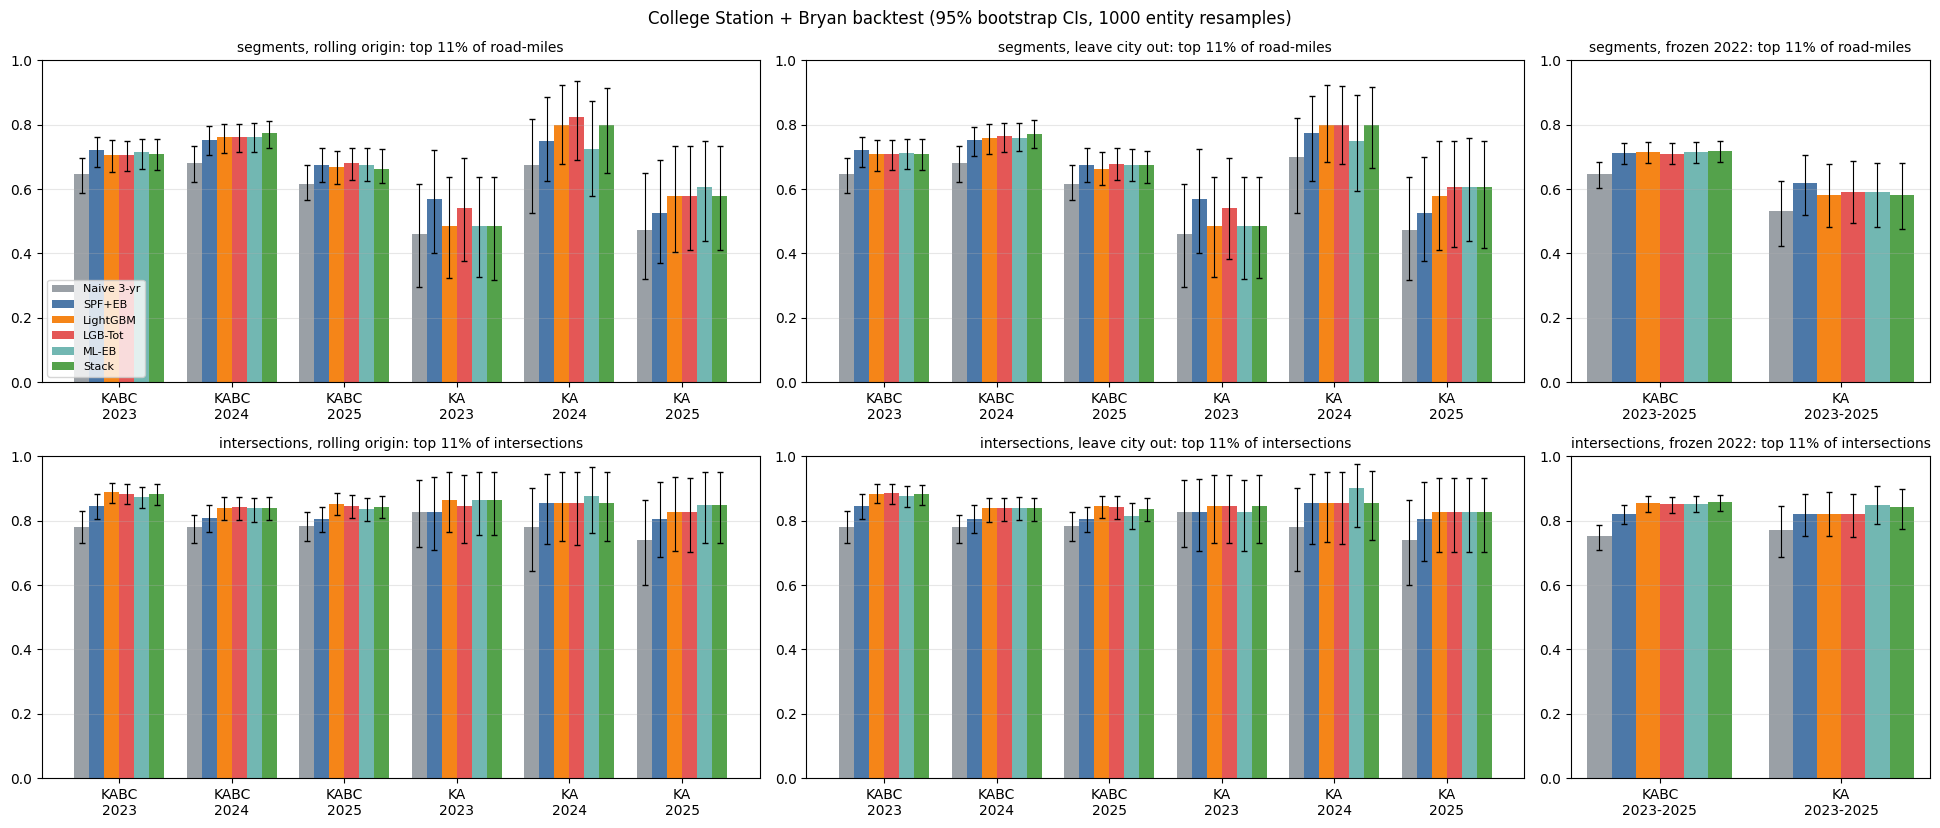

In [ ]:
kinds = list(PANELS)
scens = [s for s in ['rolling_origin', 'leave_city_out', 'frozen_2022'] if s in set(cap.scenario)]
fig, axes = plt.subplots(len(kinds), len(scens), figsize=(6.5 * len(scens), 4.2 * len(kinds)), squeeze=False,
                         gridspec_kw=dict(width_ratios=[2 if s != 'frozen_2022' else 1 for s in scens]))
colors = {'Naive 3-yr': '#9aa0a6', 'SPF+EB': '#4c78a8', 'LightGBM': '#f58518', 'LGB-Tot': '#e45756',
          'ML-EB': '#72b7b2', 'Stack': '#54a24b'}
mets = [f'capture_KABC_{FSR_TAG}', f'capture_KA_{FSR_TAG}']
for r, kind in enumerate(kinds):
    for c, scen in enumerate(scens):
        ax = axes[r][c]
        d = cap[(cap.entity_type == kind) & (cap.scenario == scen) & cap.metric.isin(mets)]
        Ts = sorted(d['T'].unique())
        groups = [(T, met) for met in mets for T in Ts]
        x = np.arange(len(groups))
        wbar = 0.8 / len(MODELS)
        for j, m in enumerate(MODELS):
            q = [d[(d['T'] == T) & (d.metric == met) & (d.model == m)] for T, met in groups]
            vals = np.array([v['value'].iloc[0] if len(v) else np.nan for v in q])
            lo = np.array([v['ci_lo'].iloc[0] if len(v) else np.nan for v in q])
            hi = np.array([v['ci_hi'].iloc[0] if len(v) else np.nan for v in q])
            ax.bar(x + (j - (len(MODELS) - 1) / 2) * wbar, vals, wbar, color=colors[m], label=m,
                   yerr=[np.nan_to_num(vals - lo), np.nan_to_num(hi - vals)], capsize=2, error_kw=dict(lw=0.8))
        ax.set_xticks(x)
        ax.set_xticklabels([f"{'KABC' if 'KABC' in met else 'KA'}\n{T}" for T, met in groups])
        unit = 'road-miles' if kind == 'segment' else 'intersections'
        ax.set_title(f'{kind}s, {scen.replace("_", " ")}: top 11% of {unit}', fontsize=10)
        ax.set_ylim(0, 1)
        ax.grid(axis='y', alpha=0.3)
        if r == 0 and c == 0:
            ax.legend(fontsize=8)
fig.suptitle(f"{' + '.join(TEST_CITIES)} backtest (95% bootstrap CIs, {C['N_BOOT']} entity resamples)")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'capture_rates.png'), dpi=130)
plt.show()


## 16. Final forecast
Retrains on every complete year and city, predicts the forecast year for the target city, and ranks by the FSR metric: expected fatal + serious (KA) crashes per mile per year (segments) or per site (intersections). Adds jurisdiction, an 11% flag, a city-actionable rank, and plain-language reasons.

In [ ]:
# plain-language names for explanations; '{v}' is the site's raw value
PRETTY = {
    'traffic': 'traffic volume ({aadt:,.0f} veh/day)', 'tot_3y': '{v:.0f} crashes of any severity in the last 3 yrs',
    'kabc_3y': '{v:.0f} injury crashes in the last 3 yrs', 'ka_3y': '{v:.0f} fatal/serious crashes in the last 3 yrs',
    'kabc_l1': '{v:.0f} injury crashes last year', 'nb_tot_3y': '{v:.0f} crashes within 250 m in the last 3 yrs',
    'nb_kabc_3y': '{v:.0f} injury crashes within 250 m in the last 3 yrs', 'SPD_MAX': '{v:.0f} mph posted speed',
    'NUM_LANES': '{v:.0f} lanes', 'legs': '{v:.0f}-leg intersection', 'signalized': 'signalized={v:.0f}',
    'dist_univ_km': '{v:.1f} km from campus', 'n_restaurant': '{v:.0f} restaurants nearby', 'n_bar': '{v:.0f} bars nearby',
    'n_school': '{v:.0f} schools nearby', 'n_crossing': '{v:.0f} marked crossings', 'signals_per_mi': '{v:.1f} signals/mi',
    'ints_per_mi': '{v:.1f} intersections/mi', 'curvature': 'curvature {v:.0f} deg/mi', 'length_mi': 'segment length {v:.2f} mi',
    'F_SYSTEM': 'functional class {v:.0f}', 'MED_TYPE': 'median type {v:.0f}', 'TRK_AADT_PCT': '{v:.0f}% trucks',
    'frontage': 'frontage road={v:.0f}', 'tot_5y': '{v:.0f} crashes of any severity in the last 5 yrs',
    'kabc_5y': '{v:.0f} injury crashes in the last 5 yrs', 'ka_5y': '{v:.0f} fatal/serious crashes in the last 5 yrs',
    'hist_years': '{v:.0f} yrs of crash history', 'pedbike_3y': '{v:.0f} pedestrian/bike crashes in the last 3 yrs',
    'angle_3y': '{v:.0f} angle crashes in the last 3 yrs', 'opp_dir_3y': '{v:.0f} opposite-direction crashes in the last 3 yrs',
    'single_veh_3y': '{v:.0f} single-vehicle crashes in the last 3 yrs', 'dark_3y': '{v:.0f} crashes in the dark in the last 3 yrs',
    'n_bus_stop': '{v:.0f} bus stops nearby', 'aadt_imputed': 'traffic count estimated={v:.0f}', 'LANE_WIDTH': '{v:.0f} ft lanes',
}
TRAFFIC_COLS = {'ln_aadt', 'ln_aadt_major', 'ln_aadt_minor'}


def merge_traffic(contrib, Xf, fut):
    """LightGBM sees traffic twice: the log(exposure) offset and the ln_aadt features. Their SHAP alone says
    'busier = safer per vehicle'. Add the centered offset back so 'traffic' shows the total effect on crash count."""
    names = list(Xf.columns)
    tcols = [i for i, n in enumerate(names) if n in TRAFFIC_COLS]
    off = np.log(fut['exposure'].to_numpy())
    traffic = contrib[:, tcols].sum(1) + (off - off.mean())
    keep = [i for i in range(len(names)) if i not in tcols]
    contrib2 = np.column_stack([traffic, contrib[:, keep]])
    X2 = pd.concat([pd.Series(off, index=Xf.index, name='traffic'), Xf.iloc[:, keep]], axis=1)
    return contrib2, X2


def explain(contrib, X2, aadt, k=5):
    out = []
    for i, row in enumerate(contrib):
        parts = []
        for j in np.argsort(-np.abs(row))[:k]:
            n = X2.columns[j]
            v = X2.iloc[i, j]
            txt = PRETTY.get(n, n + ' {v}').format(v=v if pd.notna(v) else float('nan'), aadt=aadt[i])
            parts.append(f"{'raises' if row[j] > 0 else 'lowers'}: {txt}")
        out.append('; '.join(parts))
    return out


log(f'Stage: final forecast for {FORECAST_YEAR}')
FINAL, OUT_ROWS, SHAP = {}, [], {}
for kind, panel in PANELS.items():
    train = panel[(panel.year >= FIRST_LABEL_YEAR) & (panel.year <= LAST_YEAR)]
    fut = panel[(panel.year == FORECAST_YEAR) & (panel.city == TC)].reset_index(drop=True)
    assert (fut['hist_max_date'].dropna() < pd.Timestamp(FORECAST_YEAR, 1, 1)).all()
    F = fit_all(train, kind)
    w = fit_stack_weights(train, kind)
    P = predict_all(F, fut, w)
    best = BEST[kind]
    pred, pred_ka = P[best]
    eb = P['SPF+EB'][0]
    p_ka = np.where(pred > 0, pred_ka / np.maximum(pred, 1e-12), 0)
    contrib, Xf = lgb_contrib(F['lt'], fut)          # explanations from the total-crash LightGBM (richest features)
    contrib, X2 = merge_traffic(contrib, Xf, fut)
    SHAP[kind] = (contrib, X2)
    FINAL[kind] = dict(F=F, w=w)
    for name in ['lg', 'lt', 'me']:
        for i, b in enumerate(F[name]['boosters']):
            b.save_model(os.path.join(OUT_DIR, f'lightgbm_{name}_{kind}_seed{i}.txt'))
    with open(os.path.join(OUT_DIR, f'models_{kind}.pkl'), 'wb') as f:
        pickle.dump(dict(spf=F['spf'], s1=F['s1'], s2=F['s2'], mleb_k=F['me']['k'], stack_w=w, stack_base=STACK_BASE), f)
    ent = (segs if kind == 'segment' else ints).set_index('entity_id').loc[fut['entity_id']]
    aadt = (fut['aadt'] if kind == 'segment' else fut['aadt_major'] + fut['aadt_minor']).to_numpy()
    if kind == 'segment':
        pt = gpd.GeoSeries(shapely.line_interpolate_point(ent.geometry.values, 0.5, normalized=True), crs=CRS_M).to_crs(4326)
    else:
        pt = gpd.GeoSeries(ent.geometry.values, crs=CRS_M).to_crs(4326)
    pred_ka = pred * p_ka
    out = pd.DataFrame({
        **{f'pred_ka_{m}': P[m][1].round(5) for m in MODELS},
        'entity_id': fut['entity_id'], 'entity_type': kind, 'road_name': ent['road_name'].to_numpy(),
        'jurisdiction': ent['jurisdiction'].to_numpy(),
        'lat': pt.y.to_numpy().round(6), 'lon': pt.x.to_numpy().round(6),
        'length_mi': fut['length_mi'].to_numpy().round(4) if kind == 'segment' else np.nan,
        'aadt': aadt.round(0), 'aadt_imputed': fut['aadt_imputed'].to_numpy(), 'functional_class': fut['F_SYSTEM'].to_numpy(),
        'speed_limit': fut['SPD_MAX'].to_numpy(), 'model': best,
        'tot_last_3y': fut['tot_3y'].to_numpy(), 'nb_tot_3y': fut['nb_tot_3y'].to_numpy(), 'legs': fut['legs'].to_numpy() if 'legs' in fut else np.nan,
        'pred_kabc': pred.round(5), 'p_ka_given_injury': p_ka.round(4), 'pred_ka': pred_ka.round(5),
        'fsi_rate': (pred_ka / fut['length_mi'].to_numpy()).round(5) if kind == 'segment' else pred_ka.round(5),
        'p_at_least_one_kabc': (1 - np.exp(-pred)).round(5),
        'eb_estimate': eb.round(5), 'kabc_last_3y': fut['kabc_3y'].to_numpy(), 'ka_last_3y': fut['ka_3y'].to_numpy(),
        'why': explain(contrib, X2, aadt),
    })
    # FSR ranking metric: expected F&SI (KA) per mile per year for segments, per site for intersections
    out['rank'] = 0
    out.loc[rank_order(out['fsi_rate'].to_numpy(), C['SEED']), 'rank'] = np.arange(1, len(out) + 1)
    out['rank_kabc'] = 0
    out.loc[rank_order(score_for_rank(pred, fut, kind), C['SEED']), 'rank_kabc'] = np.arange(1, len(out) + 1)
    size = out['length_mi'].to_numpy() if kind == 'segment' else np.ones(len(out))
    out['flagged_11pct'] = top_by_budget(out['fsi_rate'].to_numpy(), size, 0.11 * size.sum(), C['SEED'])
    city_only = out['jurisdiction'] != 'TxDOT'
    out['rank_city_actionable'] = np.nan
    co = out[city_only]
    out.loc[co.index[rank_order(co['fsi_rate'].to_numpy(), C['SEED'])], 'rank_city_actionable'] = np.arange(1, len(co) + 1)
    if HIN_MEMBERS is not None:
        out['in_hin'] = out['entity_id'].isin(HIN_MEMBERS['seg' if kind == 'segment' else 'int'])
    OUT_ROWS.append(out)
    log(f'  {kind}: model={best}, {len(out)} entities, predicted KABC {pred.sum():.1f}, KA {pred_ka.sum():.1f}, '
        f"EB KABC {eb.sum():.1f} | stack w {dict(zip(STACK_BASE, np.round(w, 2).tolist()))} | "
        f"jurisdiction {out['jurisdiction'].value_counts().to_dict()}")

ranking = pd.concat(OUT_ROWS, ignore_index=True).sort_values(['entity_type', 'rank'])
lead = ['entity_id', 'entity_type', 'road_name', 'jurisdiction', 'rank', 'rank_city_actionable', 'flagged_11pct',
        'pred_ka', 'fsi_rate', 'pred_kabc', 'p_ka_given_injury']
ranking = ranking[[c for c in lead if c in ranking] + [c for c in ranking if c not in lead]]
assert ranking['pred_kabc'].ge(0).all() and ranking['pred_kabc'].notna().all()
ranking.to_csv(os.path.join(OUT_DIR, 'cs_risk_ranking.csv'), index=False)
log(f'  cs_risk_ranking.csv: {len(ranking)} rows')
SHOW = ['entity_type', 'road_name', 'jurisdiction', 'pred_ka', 'fsi_rate', 'pred_kabc', 'ka_last_3y', 'rank', 'why']
# sanity check: does any top site predict far more injury crashes than its own history supports?
chk = ranking[ranking['rank'] <= 10].copy()
chk['pred_vs_hist'] = chk['pred_kabc'] / np.maximum(chk['kabc_last_3y'] / 3, 1 / 3)
log('Top-10 sanity check (pred_vs_hist > 3 deserves a look):\n' + chk[['entity_type', 'road_name', 'pred_kabc', 'kabc_last_3y',
    'tot_last_3y', 'nb_tot_3y', 'aadt', 'aadt_imputed', 'legs', 'pred_vs_hist']].round(2).to_string(index=False))
print('Top 10 overall (FSR metric, KA):')
display(ranking.groupby('entity_type').head(10)[SHOW])
print('Top 10 the City can act on alone (not TxDOT-only):')
display(ranking[ranking.jurisdiction != 'TxDOT'].sort_values(['entity_type', 'rank_city_actionable'])
        .groupby('entity_type').head(10)[SHOW])


Stage: final forecast for 2026
  segment: model=Stack, 2352 entities, predicted KABC 211.4, KA 17.7, EB KABC 277.1 | stack w {'SPF+EB': 0.0, 'LightGBM': 0.5, 'LGB-Tot': 0.0, 'ML-EB': 0.35} | jurisdiction {'City': 2030, 'TxDOT': 322}
  intersection: model=Stack, 2543 entities, predicted KABC 351.7, KA 28.5, EB KABC 357.4 | stack w {'SPF+EB': 0.02, 'LightGBM': 0.53, 'LGB-Tot': 0.08, 'ML-EB': 0.39} | jurisdiction {'City': 2111, 'Shared': 422, 'TxDOT': 10}
  cs_risk_ranking.csv: 4895 rows
Top-10 sanity check (pred_vs_hist > 3 deserves a look):
 entity_type                               road_name  pred_kabc  kabc_last_3y  tot_last_3y  nb_tot_3y     aadt  aadt_imputed  legs  pred_vs_hist
intersection                         FM2154 & FM2818       7.47          22.0         42.0       34.0  74418.0             0   3.0          1.02
intersection                            BS6 & FM2818       8.66          29.0         44.0       30.0  75206.0             0   7.0          0.90
intersection       

,entity_type,road_name,jurisdiction,pred_ka,fsi_rate,pred_kabc,ka_last_3y,rank,why
4350,intersection,FM2154 & FM2818,TxDOT,1.15717,1.15717,7.47005,3.0,1,"raises: traffic volume (74,418 veh/day); raise..."
4540,intersection,BS6 & FM2818,Shared,0.90871,0.90871,8.65662,0.0,2,"raises: traffic volume (75,206 veh/day); raise..."
2889,intersection,BS6 & HOLLEMAN DR,Shared,0.73046,0.73046,6.48750,3.0,3,"raises: traffic volume (57,183 veh/day); raise..."
3492,intersection,BS6 & SOUTHWEST PKWY,Shared,0.70364,0.70364,7.89908,2.0,4,"raises: traffic volume (59,190 veh/day); raise..."
2819,intersection,FM2818 & WELSH AVE,Shared,0.65396,0.65396,5.51008,1.0,5,"raises: traffic volume (43,942 veh/day); raise..."
3871,intersection,Penberthy Boulevard & Tom Chandler Road,City,0.63635,0.63635,3.50346,1.0,6,raises: 11 crashes of any severity in the last...
3870,intersection,Olsen Boulevard & Tom Chandler Road,City,0.60636,0.60636,4.96003,1.0,7,raises: 12 crashes of any severity in the last...
4549,intersection,SH6 & FM60,TxDOT,0.60400,0.60400,6.32978,1.0,8,"raises: traffic volume (112,612 veh/day); rais..."
3045,intersection,FM2154 & ROCK PRAIRE RD,Shared,0.52593,0.52593,5.03151,3.0,9,"raises: traffic volume (54,208 veh/day); raise..."
3321,intersection,FM2154 & HOLLEMAN DR,Shared,0.44906,0.44906,4.37973,2.0,10,"raises: traffic volume (47,773 veh/day); raise..."


Top 10 the City can act on alone (not TxDOT-only):


,entity_type,road_name,jurisdiction,pred_ka,fsi_rate,pred_kabc,ka_last_3y,rank,why
4540,intersection,BS6 & FM2818,Shared,0.90871,0.90871,8.65662,0.0,2,"raises: traffic volume (75,206 veh/day); raise..."
2889,intersection,BS6 & HOLLEMAN DR,Shared,0.73046,0.73046,6.48750,3.0,3,"raises: traffic volume (57,183 veh/day); raise..."
3492,intersection,BS6 & SOUTHWEST PKWY,Shared,0.70364,0.70364,7.89908,2.0,4,"raises: traffic volume (59,190 veh/day); raise..."
2819,intersection,FM2818 & WELSH AVE,Shared,0.65396,0.65396,5.51008,1.0,5,"raises: traffic volume (43,942 veh/day); raise..."
3871,intersection,Penberthy Boulevard & Tom Chandler Road,City,0.63635,0.63635,3.50346,1.0,6,raises: 11 crashes of any severity in the last...
3870,intersection,Olsen Boulevard & Tom Chandler Road,City,0.60636,0.60636,4.96003,1.0,7,raises: 12 crashes of any severity in the last...
3045,intersection,FM2154 & ROCK PRAIRE RD,Shared,0.52593,0.52593,5.03151,3.0,9,"raises: traffic volume (54,208 veh/day); raise..."
3321,intersection,FM2154 & HOLLEMAN DR,Shared,0.44906,0.44906,4.37973,2.0,10,"raises: traffic volume (47,773 veh/day); raise..."
4695,intersection,FM2818 & HOLLEMAN DR,Shared,0.42911,0.42911,4.95618,1.0,11,"raises: traffic volume (46,565 veh/day); raise..."
2459,intersection,BS6 & WALTON,Shared,0.42190,0.42190,2.71026,2.0,12,"raises: traffic volume (39,245 veh/day); raise..."


## 17. SHAP summary
Per-feature contributions of the total-crash LightGBM (LGB-Tot) (`pred_contrib=True`, log scale) for the forecast-year rows, colored by feature value.

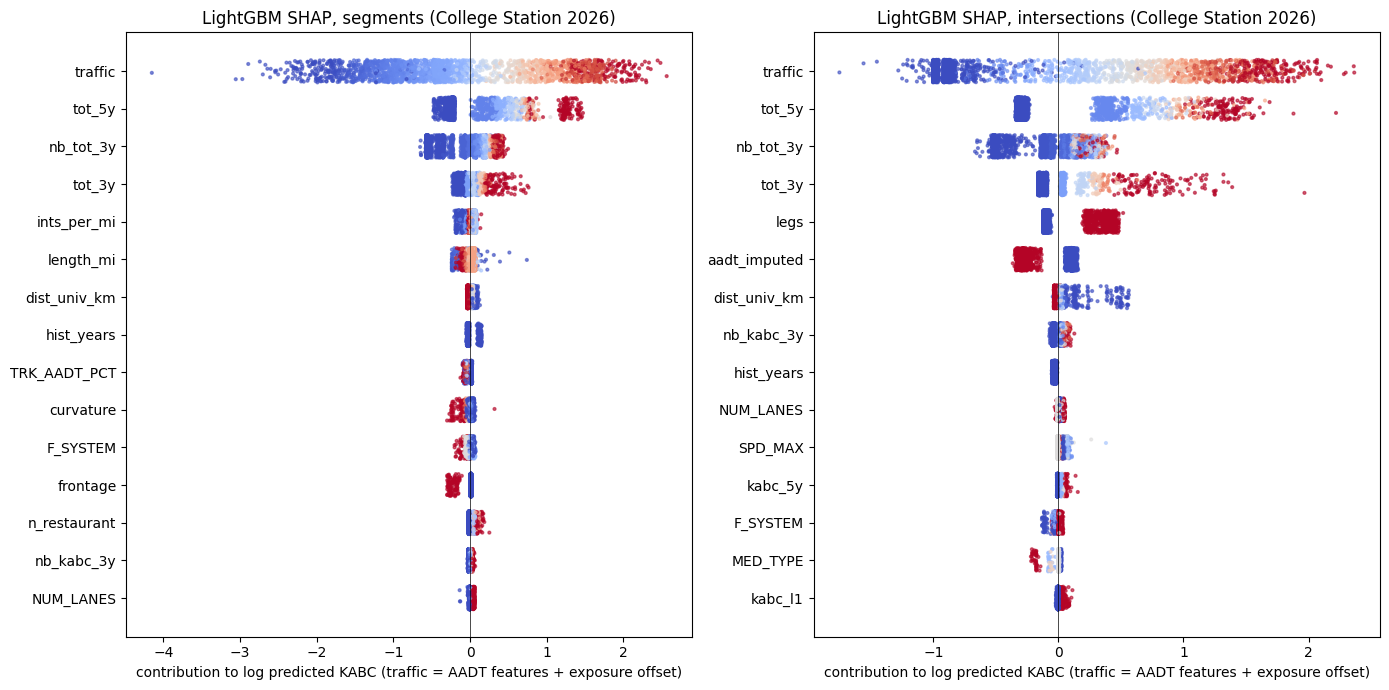

In [ ]:
fig, axes = plt.subplots(1, len(SHAP), figsize=(7 * len(SHAP), 7), squeeze=False)
for ax, (kind, (contrib, Xf)) in zip(axes[0], SHAP.items()):
    order = np.argsort(np.abs(contrib).mean(0))[-15:]
    rng = np.random.default_rng(C['SEED'])
    for k, j in enumerate(order):
        v = Xf.iloc[:, j].to_numpy(float)
        lo, hi = np.nanpercentile(v, 5) if np.isfinite(v).any() else 0, np.nanpercentile(v, 95) if np.isfinite(v).any() else 1
        col = np.clip((v - lo) / (hi - lo if hi > lo else 1), 0, 1)
        ax.scatter(contrib[:, j], k + rng.uniform(-0.3, 0.3, len(v)), c=np.nan_to_num(col, nan=0.5),
                   cmap='coolwarm', s=4, alpha=0.6)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([Xf.columns[j] for j in order])
    ax.axvline(0, color='k', lw=0.5)
    ax.set_xlabel('contribution to log predicted KABC (traffic = AADT features + exposure offset)')
    ax.set_title(f'LightGBM SHAP, {kind}s ({TC} {FORECAST_YEAR})')
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'shap_summary.png'), dpi=130)
plt.show()


## 18. Risk map
Segments colored by predicted KABC per mile, intersections as circles sized by predicted KABC. Click any feature for its CSV fields.

In [ ]:
import folium
import branca.colormap as bcm

seg_out = ranking[ranking.entity_type == 'segment'].merge(segs[['entity_id', 'geometry']], on='entity_id')
seg_out = gpd.GeoDataFrame(seg_out, geometry='geometry', crs=CRS_M).to_crs(4326)
seg_out['per_mile'] = seg_out['pred_kabc'] / seg_out['length_mi']
center = [ranking['lat'].mean(), ranking['lon'].mean()]
fmap = folium.Map(location=center, zoom_start=13, tiles='cartodbpositron')
vmax = float(np.nanpercentile(seg_out['per_mile'], 99)) or 1.0
cmap = bcm.LinearColormap(['#2c7bb6', '#ffffbf', '#fdae61', '#d7191c'], vmin=0, vmax=vmax,
                          caption='Predicted KABC crashes per mile')
popup_cols = [c for c in ranking.columns if c not in ('lat', 'lon')]


def _popup(r):
    return '<br>'.join(f'<b>{c}</b>: {r[c]}' for c in popup_cols)


fg_s = folium.FeatureGroup(name='Segments')
for _, r in seg_out.sort_values('per_mile').iterrows():
    folium.PolyLine([(y, x) for x, y in r.geometry.coords], color=cmap(min(r['per_mile'], vmax)),
                    weight=3 if r['rank'] > 0.1 * len(seg_out) else 5, opacity=0.9,
                    popup=folium.Popup(_popup(r), max_width=350)).add_to(fg_s)
fg_s.add_to(fmap)
io_ = ranking[ranking.entity_type == 'intersection']
if len(io_):
    fg_i = folium.FeatureGroup(name='Intersections')
    imax = io_['pred_kabc'].quantile(0.99) or 1.0
    for _, r in io_.sort_values('pred_kabc').iterrows():
        folium.CircleMarker((r['lat'], r['lon']), radius=2 + 10 * np.sqrt(min(r['pred_kabc'], imax) / imax),
                            color='#5e3c99', fill=True, fill_opacity=0.6, weight=1,
                            popup=folium.Popup(_popup(r), max_width=350)).add_to(fg_i)
    fg_i.add_to(fmap)
if HIN_MEMBERS is not None:
    fg_h = folium.FeatureGroup(name='MPO HIN (method A)', show=False)
    for g in segs[segs.entity_id.isin(HIN_MEMBERS['seg'])].to_crs(4326).geometry:
        folium.PolyLine([(y, x) for x, y in g.coords], color='black', weight=8, opacity=0.35).add_to(fg_h)
    fg_h.add_to(fmap)
cmap.add_to(fmap)
folium.LayerControl().add_to(fmap)
fmap.save(os.path.join(OUT_DIR, 'risk_map.html'))
log('  risk_map.html saved')

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


  risk_map.html saved


## 19. Run log
Writes data counts, drop rates, SPF fit details, and package versions to `outputs/run_log.txt`.

In [ ]:
spf_info = pd.DataFrame(FIT_INFO)
log('Model fit details per fold:\n' + spf_info.to_string(index=False))
log(f'Outputs in {OUT_DIR}: ' + ', '.join(sorted(os.listdir(OUT_DIR))))
log(f'Run finished in {(time.time() - RUN_T0) / 60:.1f} min')

Model fit details per fold:
        kind       scenario         T              spf    spf_k   mleb_k  rounds_kabc  rounds_tot  ka_factor  kabc_factor  w_SPF+EB  w_LightGBM  w_LGB-Tot  w_ML-EB
     segment rolling_origin      2023 NB2 MLE (newton) 0.843015 0.162082          591         670   0.966863     1.003251     0.008       0.657      0.000    0.434
     segment rolling_origin      2024 NB2 MLE (newton) 0.830276 0.175534          225         111   0.971483     0.987408     0.103       0.539      0.000    0.319
     segment rolling_origin      2025 NB2 MLE (newton) 0.826025 0.363572          885        1147   0.983540     0.990273     0.166       0.628      0.033    0.068
     segment leave_city_out      2023 NB2 MLE (newton) 0.868335 0.150871          518         592   1.000000     1.000000     0.000       0.641      0.000    0.437
     segment leave_city_out      2024 NB2 MLE (newton) 0.851499 0.174926          215         111   1.000000     1.000000     0.100       0.523      0.0

## Assumptions and limitations
- **Roads are static.** The current TxDOT Roadway Inventory (ADT, lanes, speed, median) is applied to every year, so road changes and traffic growth over time are not modeled.
- **Roadbeds.** KG main lanes and AG/XG frontage roads are segmented. LG/RG lines of divided highways are dropped where a KG centerline is within 60 m, since they duplicate it; crashes on either side snap to the centerline.
- **Routes** are merged by `RIA_RTE_ID` + roadbed. Branching routes yield several merged lines, each cut separately.
- **Segments and intersections are separate entities.** Intersection-related crashes count only toward intersections and never toward segments, and vice versa.
- **Crashes without a match** (no intersection within 76 m, or no segment within 50 m) are dropped and counted in the log, never forced to a farther entity. A name match only breaks ties among candidates already within tolerance.
- **AADT.** Missing segment ADT is imputed by the (city, functional class) median. Intersection AADT_major and AADT_minor come from inventory lines within 25 m; when absent they are imputed from the city's local-street ADT median or the city's median minor-road ADT. `aadt_imputed = 1` marks either case. For intersections the `aadt` column in the ranking is AADT_major + AADT_minor.
- **Speed limits** missing in the inventory are imputed by class median for modeling only; `speed_limit` in the CSV is the raw value.
- **Median type.** `divided` in the SPF means TxDOT MED_TYPE >= 2. The coding is assumed, not documented in the layer.
- **EB.** Because the inventory is static, the SPF prediction is the same in every year, so mu_sum = 3 * mu_T.
- **Restaurants** include OSM `amenity=fast_food`. Bars include pubs and nightclubs. Universities are `amenity=university` polygons within 10 km; distance is capped at 10 km.
- **OSM is current**, not historical, like the inventory.
- **Capture metric.** Entities are ranked by predicted crashes per mile (segments) or predicted crashes (intersections), with ties broken by a seeded random key. The top set is the longest prefix that does not exceed the share of road-miles (or of intersections).
- **Cities** count only if at least `MIN_CITY_CRASHES` geocoded crashes fall inside their TIGER polygon. Crashes are assigned to cities by location, not by the CRIS City column.
- **Complete years** start in January of the first data year and ended at least 6 months before the latest crash date. The first label year is the first complete year + 3.
- **Severity 99 (unknown)** crashes count in total-crash history but never in KABC labels.
- **Ranks** are within entity type (segments and intersections are ranked separately).
- **Jurisdiction** comes from the inventory highway system (`HSYS`, else the route-ID prefix) against `TXDOT_SYSTEMS`. Check the logged HSYS values once. An intersection is TxDOT only if every nearby inventory route is on-system; a state route meeting a street missing from the inventory is Shared.
- **KA ranking.** KA = predicted KABC x P(KA | KABC). P(KA) is a binomial GLM shrunk toward the site's own 3-year KA share with `SEV_PRIOR_M` pseudo-crashes.
- **Explanations.** LightGBM's AADT SHAP alone is negative at busy sites because exposure is already in the offset (fewer crashes per vehicle). The `traffic` term adds the centered offset back, so it shows the total effect on crash count.
- **HIN comparison** uses the HIN as published (or reconstructed) and matches its budget exactly; crashes dropped in assignment are outside both numerator and denominator.
- **Test cities.** Backtest scores cover College Station and Bryan; the forecast and ranking cover College Station only.
- **Stack** weights come from a fit on training years before the last one, scored on the last training year (Poisson deviance, non-negative weights). They are logged per fold.
- **Crash-type features** (ped/bike, angle, opposite-direction, single-vehicle, dark) need the matching CRIS columns; missing ones stay 0 and are logged.
- **Severity calibration.** One factor per share and site type rescales predicted shares to match the test cities' training years; leave-city-out folds use no factor.
- **Road attributes are current** (TxDOT inventory and OSM), not as of 2022, so frozen_2022 models see some post-2022 road information that the HIN did not.
